# Homework 6

**Name:** Nakul Kumbria

**GitHub Username:** nakicool007

**USC ID:** 6748597520

## Setup

In [1]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.impute import SimpleImputer

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"neg": "#3268a8", "pos": "#d75b38"}
pd.set_option("display.max_columns", 12)
%matplotlib inline

## 1. Tree-Based Methods
### (a) Load the APS Failure data

In [ ]:
DATA_DIR = next(
    (base / "data" / "aps_failure_data" for base in (Path.cwd(), *Path.cwd().parents)
     if (base / "data" / "aps_failure_data" / "aps_failure_training_set.csv").is_file()),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError("Cannot find data/aps_failure_data/aps_failure_training_set.csv")

def load_aps(filename):
    csv_path = DATA_DIR / filename
    with csv_path.open(encoding="utf-8") as file:
        header_row = next(i for i, line in enumerate(file) if line.startswith("class,"))
    frame = pd.read_csv(csv_path, skiprows=header_row, na_values=["na"])
    assert frame["class"].isin(["neg", "pos"]).all()
    return frame

train = load_aps("aps_failure_training_set.csv")
test = load_aps("aps_failure_test_set.csv")
assert train.shape == (60000, 171)
assert test.shape == (16000, 171)
assert train.columns.equals(test.columns)

X_train_raw = train.drop(columns="class")
X_test_raw = test.drop(columns="class")
y_train = train["class"].map({"neg": 0, "pos": 1})
y_test = test["class"].map({"neg": 0, "pos": 1})
assert X_train_raw.select_dtypes(include="number").shape[1] == 170
display(pd.DataFrame({"rows": [len(train), len(test)],
                      "features": [170, 170], "total_columns": [171, 171]},
                     index=["training", "test"]))
display(train.head())

,rows,features,total_columns
training,60000,170,171
test,16000,170,171


,class,aa_000,ab_000,ac_000,ad_000,ae_000,...,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,...,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,...,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,...,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,...,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,...,286954.0,311560.0,433954.0,1218.0,0.0,0.0


### (b)(i) Missing values: research and imputation
Common approaches include:

* **Mean, median, mode, or constant imputation:** replace a missing entry with a
  summary of its feature. Mean/median suit numeric features; mode also suits categories.
* **K-nearest-neighbor imputation:** estimate missing entries from similar observations.
  Distances depend on scaling, and neighbor searches can be expensive on this dataset.
* **Iterative/model-based imputation:** predict each incomplete feature from the other
  features, cycling through the columns. This can capture dependencies but costs more
  computation and introduces modeling assumptions. Multiple imputation generates
  several completed datasets to account for uncertainty rather than a single fill.

I use **per-feature median imputation**: it retains all observations and all 170 features,
is inexpensive, and is less sensitive to extreme values than mean imputation. It is
a baseline: it can reduce variability, alter correlations, and cannot recover the true
missing values or their uncertainty. Missingness indicators could be considered later.

Fit the imputer **only on training data**, then apply the learned training medians to
both splits. In later cross-validation it must be refitted inside each training fold,
and any SMOTE step must also stay inside those folds. The assignment's footnote appears
to reverse training and test: using test statistics during training would leak information.

References: [scikit-learn imputation guide](https://scikit-learn.org/stable/modules/impute.html)
and [SimpleImputer documentation](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html).

In [ ]:
missing_summary = pd.DataFrame({
    "missing_count": X_train_raw.isna().sum(),
    "missing_percent": 100 * X_train_raw.isna().mean(),
}).sort_values("missing_percent", ascending=False)
display(missing_summary.head(15).round(2))
display(Markdown(
    f"Training data contain **{X_train_raw.isna().sum().sum():,} missing feature entries** "
    f"({100 * X_train_raw.isna().to_numpy().mean():.2f}% of all feature entries). "
    f"Deleting every incomplete row would retain only "
    f"**{X_train_raw.dropna().shape[0]:,} of {len(train):,} rows**."
))
assert not X_train_raw.isna().all().any()
imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(imputer.fit_transform(X_train_raw),
                       columns=X_train_raw.columns, index=X_train_raw.index)
X_test = pd.DataFrame(imputer.transform(X_test_raw),
                      columns=X_test_raw.columns, index=X_test_raw.index)
assert X_train.shape == (60000, 170) and X_test.shape == (16000, 170)
assert np.isfinite(X_train.to_numpy()).all()
assert np.isfinite(X_test.to_numpy()).all()
print("Missing values after imputation:",
      {"train": int(X_train.isna().sum().sum()), "test": int(X_test.isna().sum().sum())})

,missing_count,missing_percent
br_000,49264,82.11
bq_000,48722,81.20
bp_000,47740,79.57
bo_000,46333,77.22
ab_000,46329,77.22
cr_000,46329,77.22
bn_000,44009,73.35
bm_000,39549,65.92
bl_000,27277,45.46
bk_000,23034,38.39


Training data contain **850,015 missing feature entries** (8.33% of all feature entries). Deleting every incomplete row would retain only **591 of 60,000 rows**.

Missing values after imputation: {'train': 0, 'test': 0}


### (b)(ii) Coefficient of variation for all 170 features
For each imputed training feature, compute $CV=s/m$, with sample standard deviation
$s$ (`ddof=1`) and sample mean $m$. CV is dimensionless and is reported as a ratio,
not a percentage. It is undefined for a zero mean and unstable for a near-zero mean.
The complete table is displayed below in descending order. These CVs describe the
**median-imputed training data**, so imputation affects the results.

In [4]:
feature_stats = pd.DataFrame({
    "mean": X_train.mean(),
    "sample_std": X_train.std(ddof=1),
})
feature_stats["CV"] = feature_stats["sample_std"].div(
    feature_stats["mean"].where(feature_stats["mean"].ne(0))
)
feature_stats = feature_stats.sort_values("CV", ascending=False)
assert len(feature_stats) == 170
with pd.option_context("display.max_rows", 170):
    display(feature_stats.round(6))
print("Features with undefined CV:", feature_stats.index[feature_stats["CV"].isna()].tolist())

,mean,sample_std,CV
cf_000,1.431075e+05,3.504525e+07,244.887517
co_000,1.433300e+05,3.504525e+07,244.507385
ad_000,1.434383e+05,3.504525e+07,244.322816
cs_009,7.705097e+02,1.833278e+05,237.930554
dh_000,4.392641e+03,5.412441e+05,123.216097
dj_000,3.727133e+01,4.379166e+03,117.494225
ag_000,2.191577e+02,2.036364e+04,92.917755
as_000,1.254079e+02,1.095219e+04,87.332500
ay_009,1.149620e+03,9.741156e+04,84.733735
ak_000,9.076607e+02,7.299859e+04,80.424975


Features with undefined CV: []


### (b)(iii) Feature correlation matrix
Pearson correlations use all **60,000 training observations** and **170 imputed
features**, excluding the class label. The compact overview shows a label every ten
features; the numeric `correlation_matrix` retains all feature names. White represents
correlations near zero, blue negative correlations, and red positive correlations.
The second plot enlarges the strongest feature pairs for easier comparison.

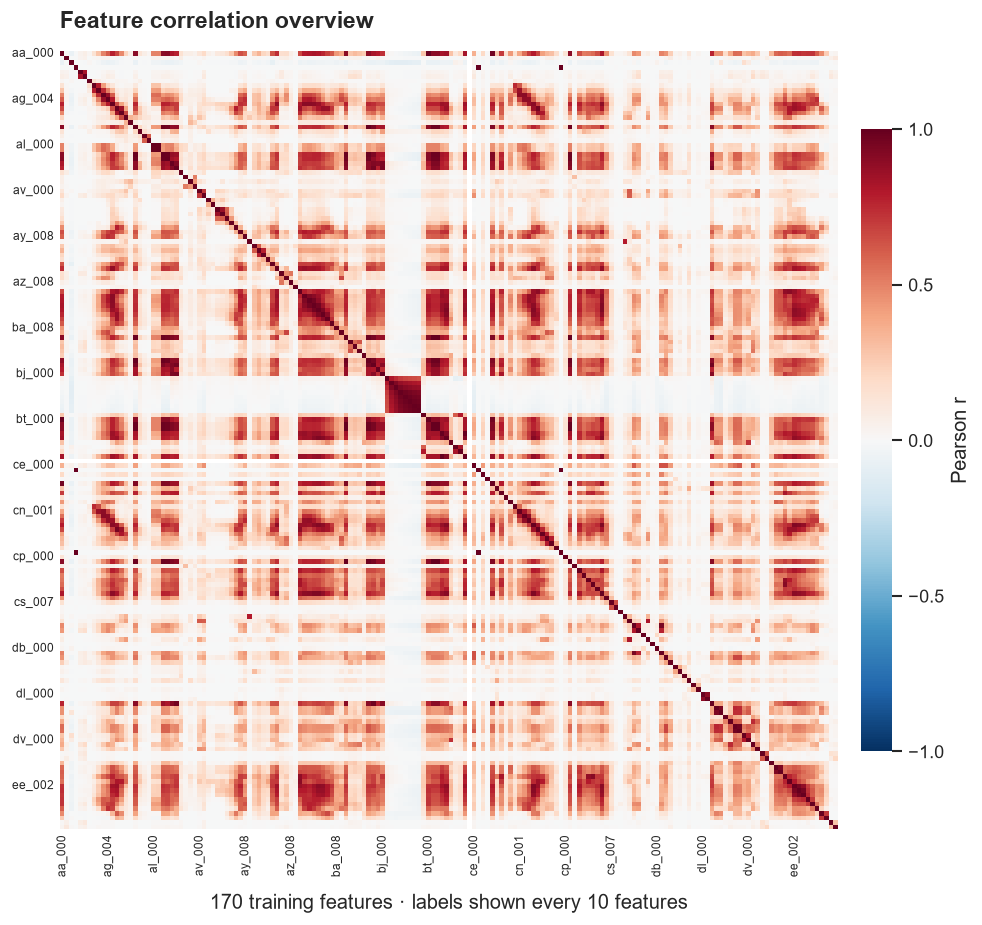

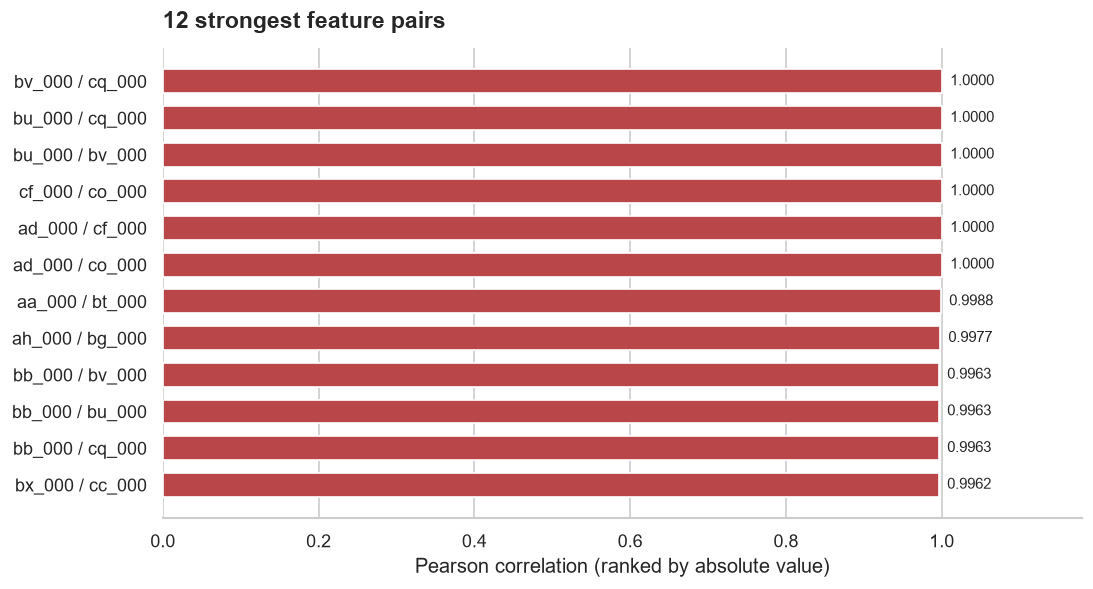

In [ ]:
correlation_matrix = X_train.corr(method="pearson")

with sns.axes_style("white"), plt.rc_context({"figure.dpi": 120, "font.size": 9}):
    fig, ax = plt.subplots(figsize=(9, 7.6), layout="constrained")
    sns.heatmap(
        correlation_matrix, ax=ax, cmap="RdBu_r", vmin=-1, vmax=1, center=0,
        square=True, xticklabels=10, yticklabels=10, rasterized=True,
        cbar_kws={"label": "Pearson r", "shrink": 0.8, "pad": 0.025,
                  "ticks": [-1, -0.5, 0, 0.5, 1]},
    )
    ax.set_title("Feature correlation overview", loc="left", fontsize=14,
                 fontweight="bold", pad=14)
    ax.set_xlabel("170 training features · labels shown every 10 features", labelpad=10)
    ax.set_ylabel("")
    ax.tick_params(axis="both", length=0, labelsize=7)
    plt.setp(ax.get_xticklabels(), rotation=90, ha="center")
    plt.setp(ax.get_yticklabels(), rotation=0)
    plt.show()
upper = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)
strongest_correlations = upper.stack().rename("correlation").sort_values(
    key=lambda values: values.abs(), ascending=False
)
top_pairs = strongest_correlations.head(12)
pair_labels = [f"{left} / {right}" for left, right in top_pairs.index]
with sns.axes_style("whitegrid"), plt.rc_context({"figure.dpi": 120}):
    fig, ax = plt.subplots(figsize=(9, 4.8), layout="constrained")
    bars = ax.barh(pair_labels, top_pairs.to_numpy(), height=0.65,
                   color=["#b94749" if r >= 0 else "#3478a8" for r in top_pairs])
    ax.invert_yaxis()
    ax.set_xlim(-1.03 if top_pairs.lt(0).any() else 0, 1.18)
    ax.bar_label(bars, labels=[f"{r:.4f}" for r in top_pairs], padding=5, fontsize=9)
    ax.set_title("12 strongest feature pairs", loc="left", fontsize=14,
                 fontweight="bold", pad=12)
    ax.set_xlabel("Pearson correlation (ranked by absolute value)")
    ax.set_ylabel("")
    ax.grid(axis="y", visible=False)
    ax.set_axisbelow(True)
    sns.despine(ax=ax, left=True)
    plt.show()


Large positive blocks indicate correlated groups, so some features may contain
redundant information. Pearson correlation measures linear association, is sensitive
to extreme observations, and can change after imputation. It does not establish
causation or tell us which features predict APS failure best.

### (b)(iv) Visualize the features with highest CV
Used $\lfloor\sqrt{170}\rfloor=13$ features, selected by CV on the training set only.
This is **only a visualization subset**; `X_train` and `X_test` retain all 170 features.

In [6]:
n_visual_features = math.isqrt(X_train.shape[1])
top_features = feature_stats["CV"].dropna().head(n_visual_features).index.tolist()
assert len(top_features) == 13
display(feature_stats.loc[top_features].round(6))
print("Selected features:", ", ".join(top_features))

,mean,sample_std,CV
cf_000,143107.534133,3.504525e+07,244.887517
co_000,143330.017733,3.504525e+07,244.507385
ad_000,143438.292067,3.504525e+07,244.322816
cs_009,770.509700,1.833278e+05,237.930554
dh_000,4392.640833,5.412441e+05,123.216097
dj_000,37.271333,4.379166e+03,117.494225
ag_000,219.157733,2.036364e+04,92.917755
as_000,125.407900,1.095219e+04,87.332500
ay_009,1149.619633,9.741156e+04,84.733735
ak_000,907.660700,7.299859e+04,80.424975


Selected features: cf_000, co_000, ad_000, cs_009, dh_000, dj_000, ag_000, as_000, ay_009, ak_000, az_009, ch_000, au_000


The scatterplot matrix covers every pair of selected features. To make sparse,
heavy-tailed measurements readable, its axes use **log(1 + value)**; zeros remain zero.
For plotting only, use a reproducible stratified sample of up to 3,000 negatives and
1,000 positives. This deliberately increases the visible minority fraction, so point
densities do **not** represent population class proportions. Neither CV calculations
nor correlation calculations use this sample. Histograms on the diagonal show each
class separately, normalized within class.

label
neg    3000
pos    1000
Name: scatterplot_sample_count, dtype: int64

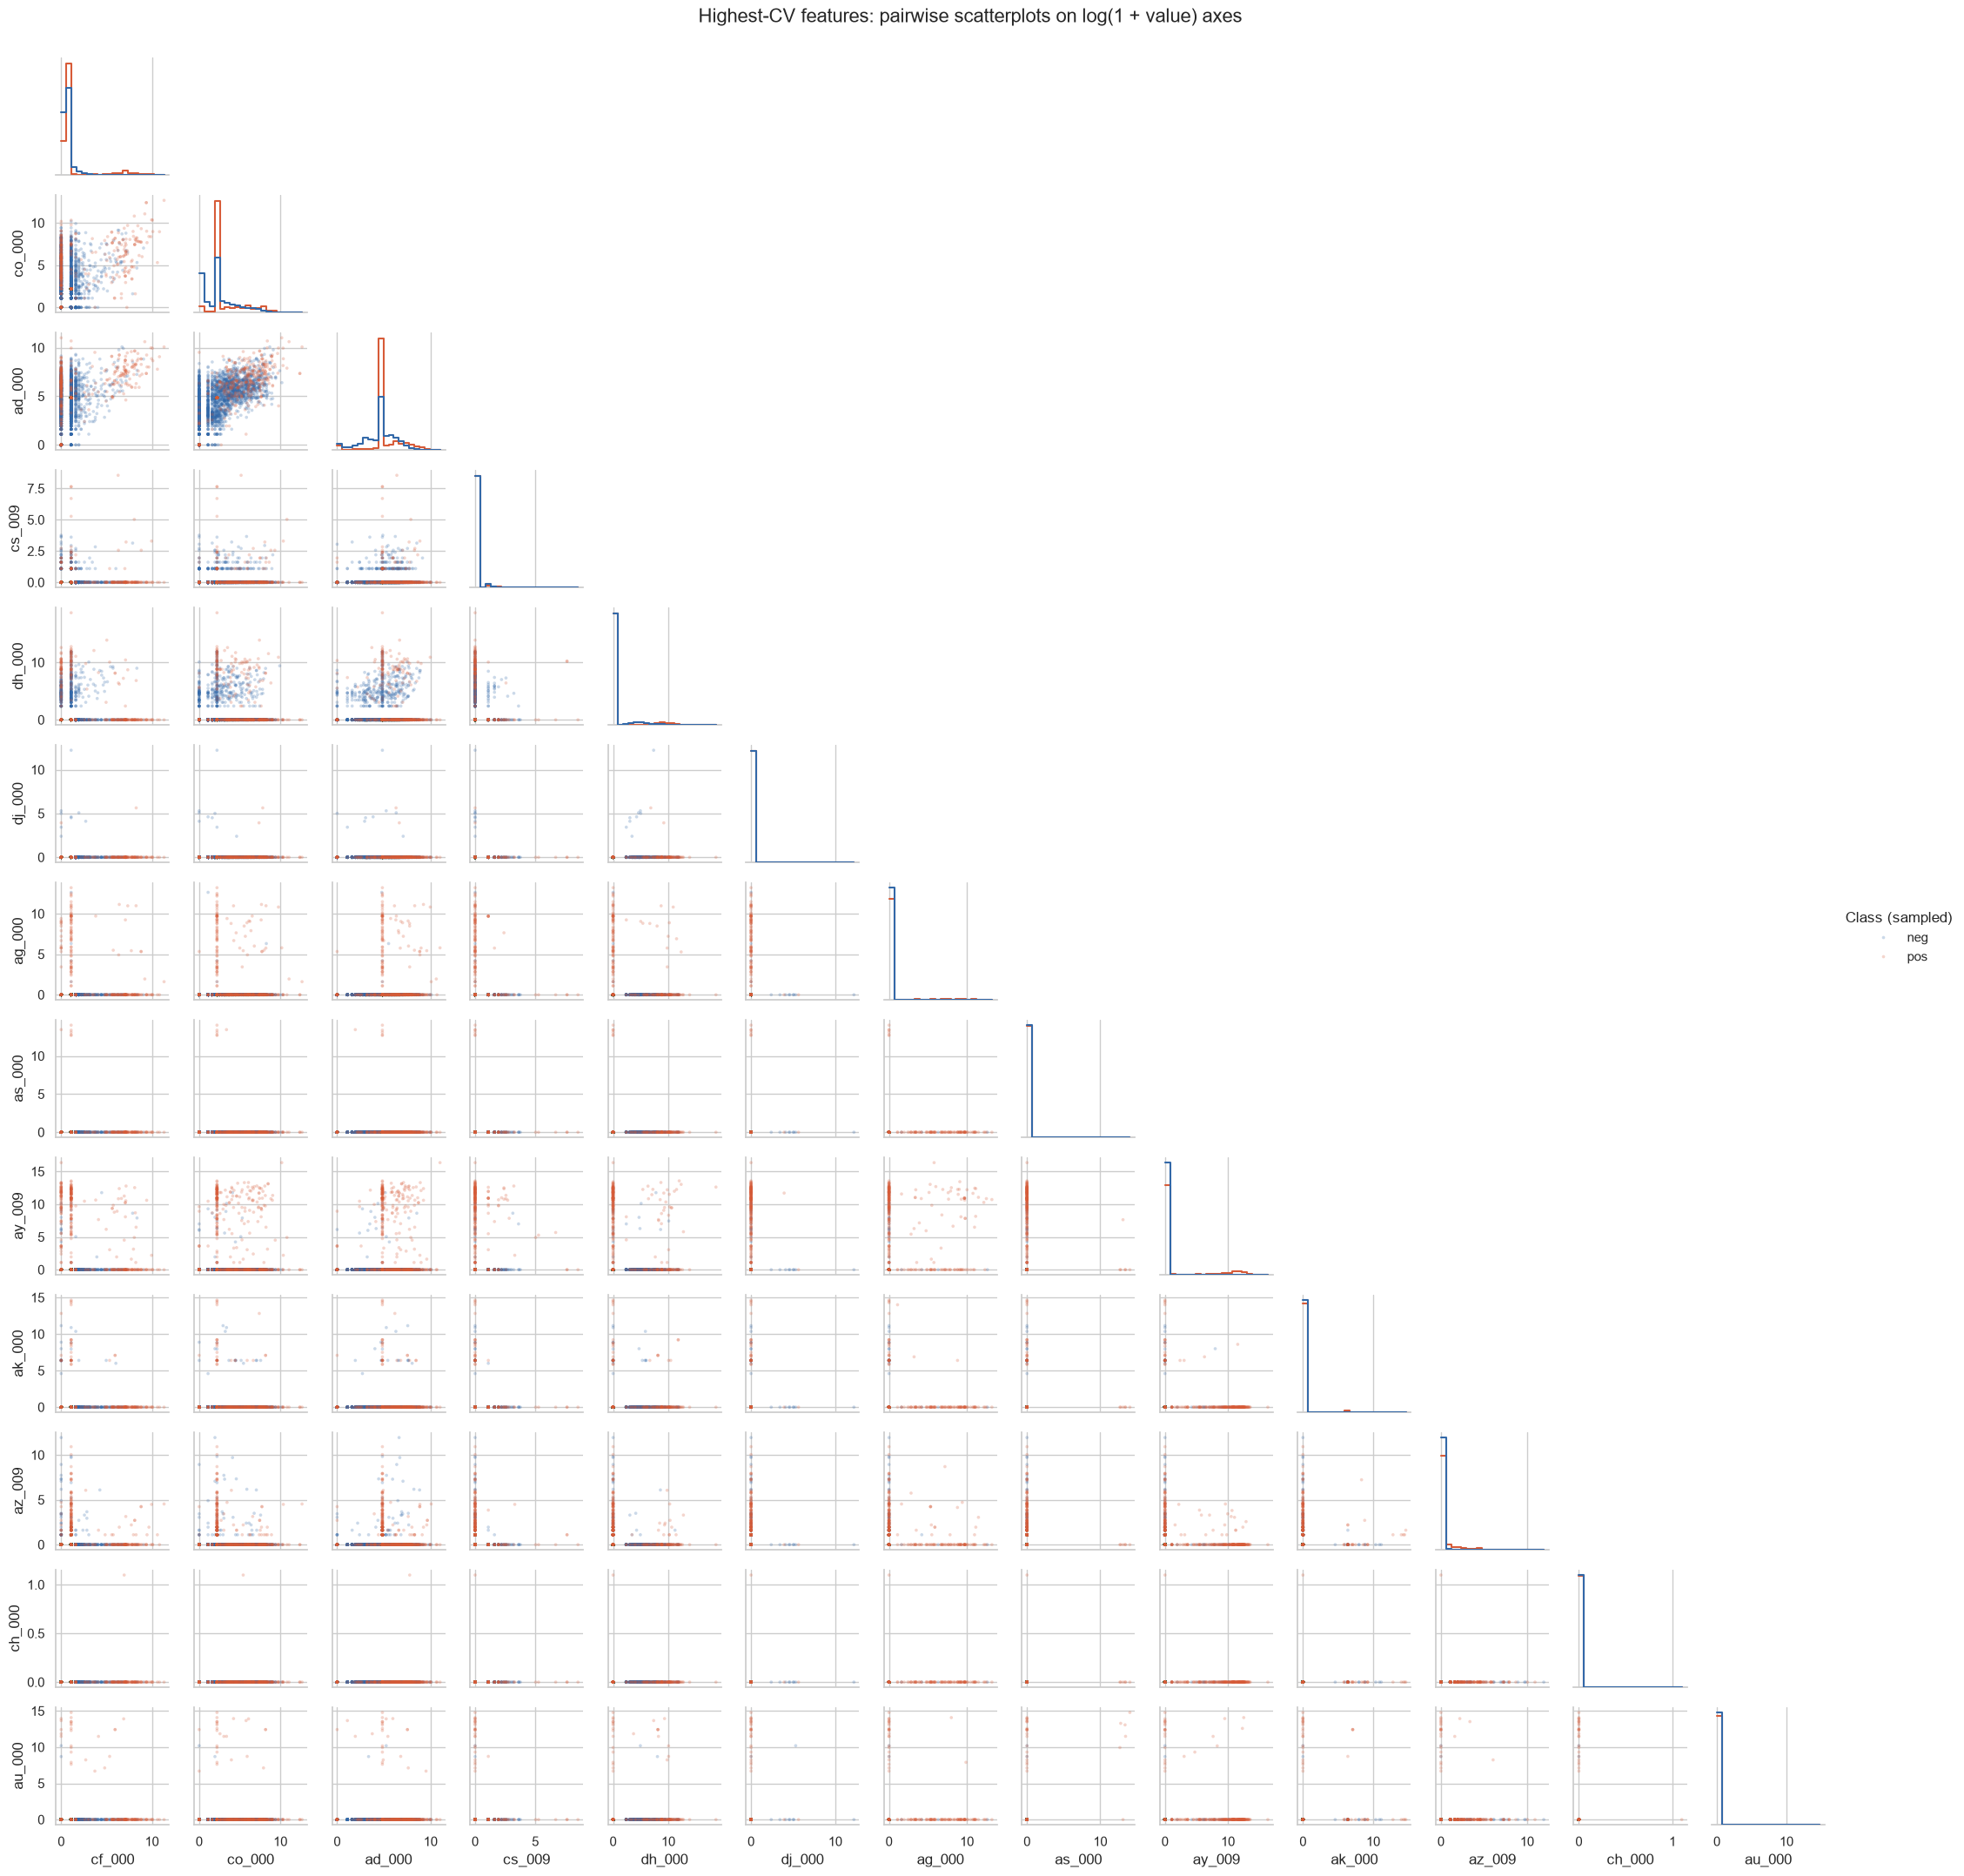

In [7]:
assert (X_train[top_features] >= 0).all().all()
plot_data = np.log1p(X_train[top_features]).assign(label=train["class"])
scatter_sample = pd.concat([
    plot_data.loc[plot_data["label"].eq(label)].sample(
        n=min(limit, int(plot_data["label"].eq(label).sum())), random_state=RANDOM_STATE
    )
    for label, limit in [("neg", 3000), ("pos", 1000)]
])
display(scatter_sample["label"].value_counts().rename("scatterplot_sample_count"))
g = sns.PairGrid(scatter_sample, vars=top_features, hue="label",
                 hue_order=["neg", "pos"], palette=PALETTE,
                 corner=True, height=1.65, diag_sharey=False)
g.map_lower(sns.scatterplot, s=7, alpha=0.25, linewidth=0, rasterized=True)
g.map_diag(sns.histplot, bins=20, stat="density", element="step", fill=False,
           common_norm=False)
g.add_legend(title="Class (sampled)")
g.figure.suptitle("Highest-CV features: pairwise scatterplots on log(1 + value) axes",
                  y=1.01, fontsize=16)
plt.show()

The class-wise boxplots below use **all training observations** and the same
log(1 + value) transformation. Outliers are displayed with small transparent markers.
Because the transformation is monotone, it preserves order while compressing the
large values. A collapsed box indicates that many observations have the same value
(often zero); the scatterplots help expose the remaining tail.

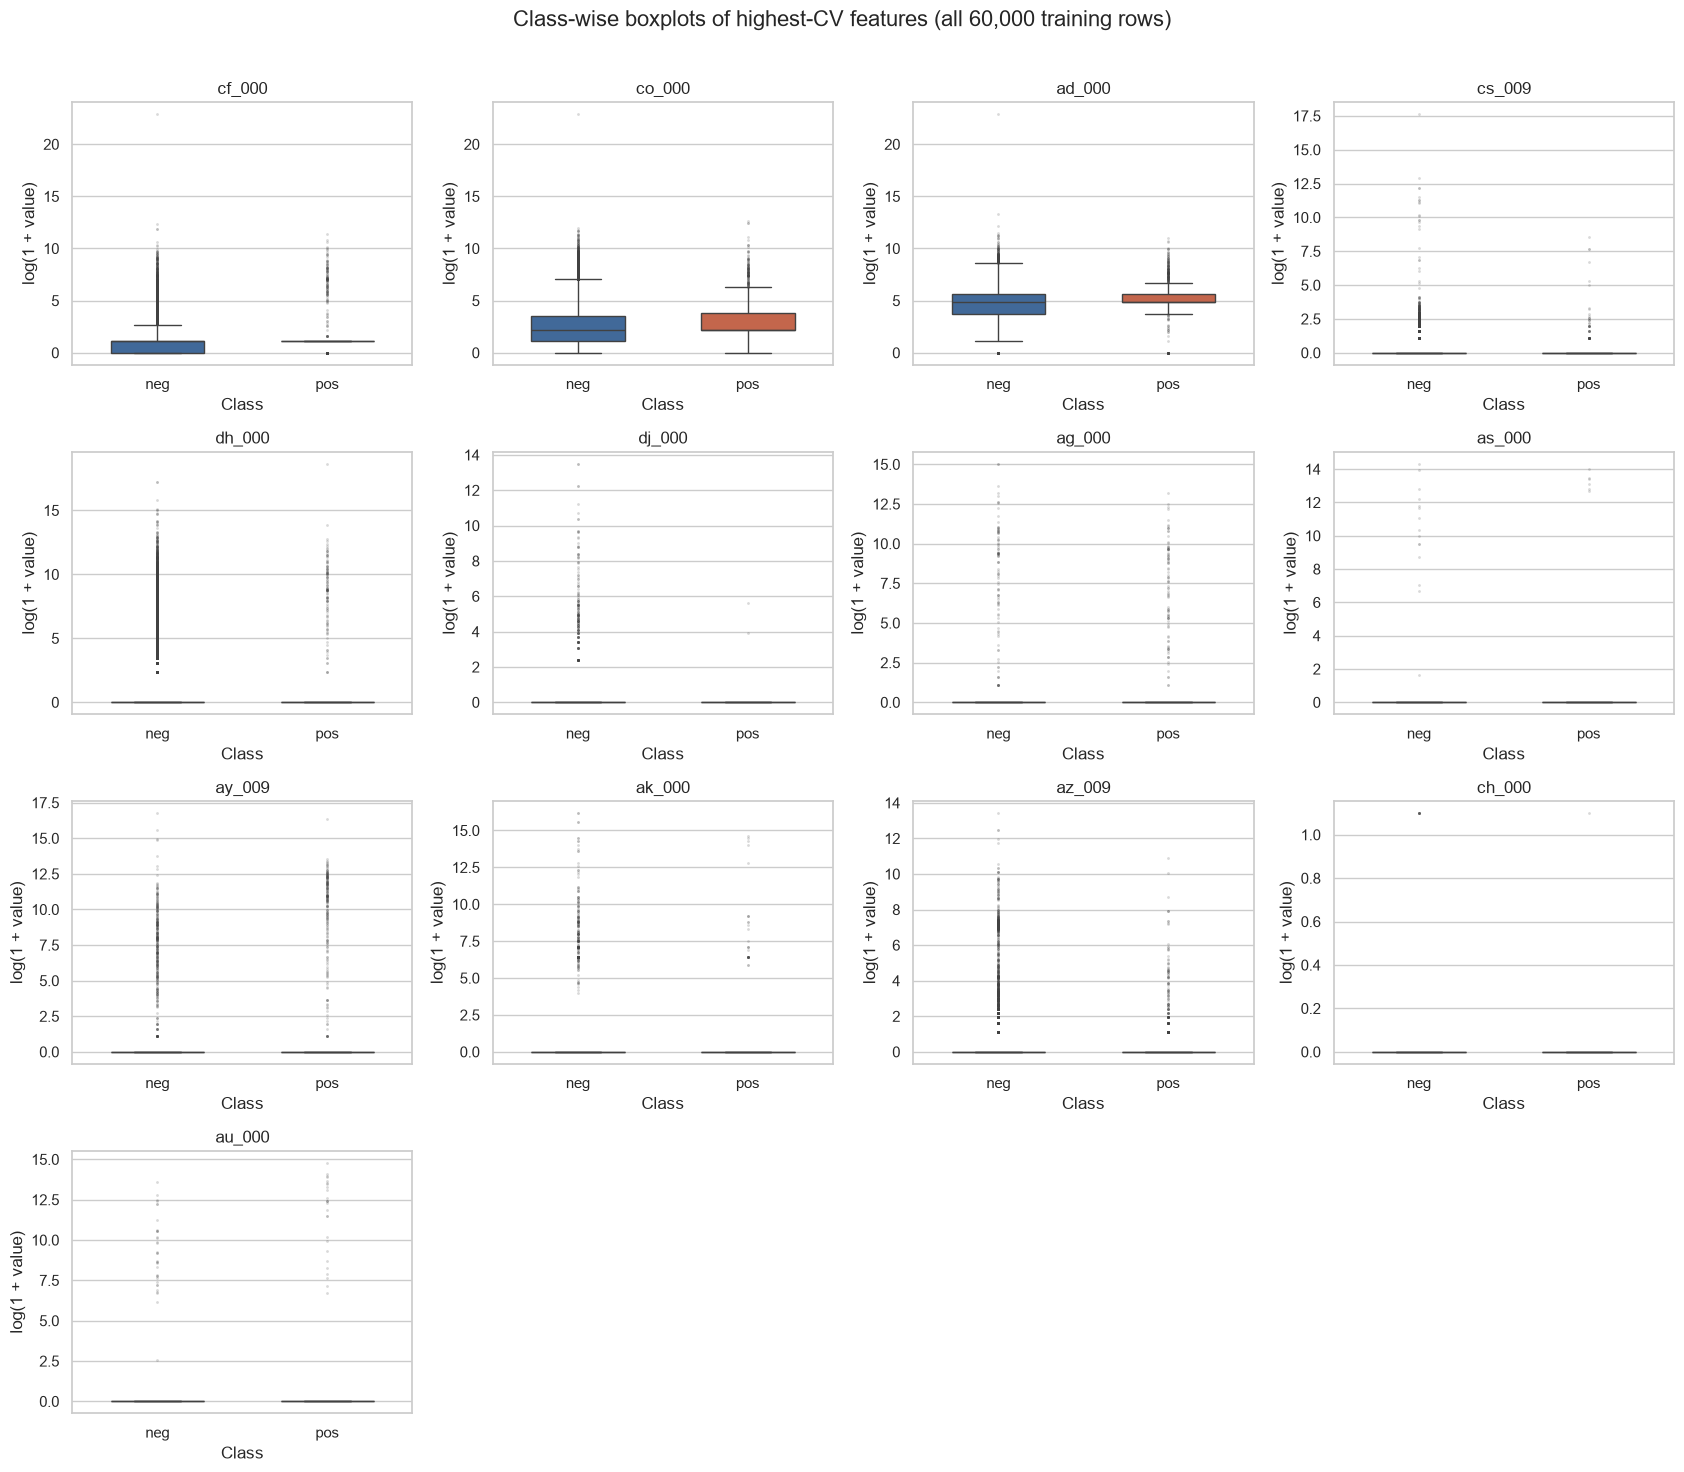

class,neg_zero_percent,pos_zero_percent
cf_000,36.04,20.4
co_000,21.62,3.6
ad_000,3.36,2.7
cs_009,95.17,94.8
dh_000,88.36,88.1
dj_000,99.67,99.8
ag_000,99.83,90.3
as_000,99.97,99.4
ay_009,99.44,79.3
ak_000,99.42,96.9


In [ ]:
fig, axes = plt.subplots(4, 4, figsize=(17, 15))
for ax, feature in zip(axes.flat, top_features):
    sns.boxplot(data=plot_data, x="label", y=feature, order=["neg", "pos"],
                hue="label", hue_order=["neg", "pos"], palette=PALETTE, legend=False,
                ax=ax, width=0.55,
                flierprops={"marker": ".", "markersize": 2, "alpha": 0.2})
    ax.set_title(feature)
    ax.set_xlabel("Class")
    ax.set_ylabel("log(1 + value)")
for ax in axes.flat[len(top_features):]:
    ax.set_visible(False)
fig.suptitle("Class-wise boxplots of highest-CV features (all 60,000 training rows)",
             fontsize=16)
plt.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

zero_rates = X_train[top_features].eq(0).groupby(train["class"]).mean().T * 100
display(zero_rates.rename(columns={"neg": "neg_zero_percent", "pos": "pos_zero_percent"}).round(2))

**Observed patterns.** Many selected features are dominated by zeros and have long right tails, explaining their collapsed boxes and high CVs. For example, ay_009 is zero in 99.44% of negatives versus 79.30% of positives; ag_000 is zero in 99.83% versus 90.30%. These differences suggest possible predictive information, but substantial class overlap remains. The co_000 and ad_000 scatterplot also shows a strong positive relationship, suggesting redundancy. These are exploratory observations on imputed data.

**Can scatterplots alone establish feature significance? No.** High CV measures
relative spread, not association with the target. A rare large value and a very small
mean can produce a high CV even for an unhelpful predictor. The plots let us inspect
zero concentrations, tails, overlap, and possible class differences, but visual
separation is neither a statistical significance test nor a measure of predictive
value. Sampling, overplotting, class imbalance, and correlated predictors complicate
interpretation. Validate usefulness with appropriate held-out or cross-validated
performance and feature importance; use a defined hypothesis test (with multiple-test
correction where appropriate) if formal statistical significance is the goal.

### (b)(v) Positive and negative counts: is the data imbalanced?
Counts are computed on the original labels before any resampling. Test counts are
reported for completeness; they are not used to fit preprocessing or choose features.

class,neg,pos,positive_percent,negative_to_positive_ratio
training,59000,1000,1.667,59.000
test,15625,375,2.344,41.667


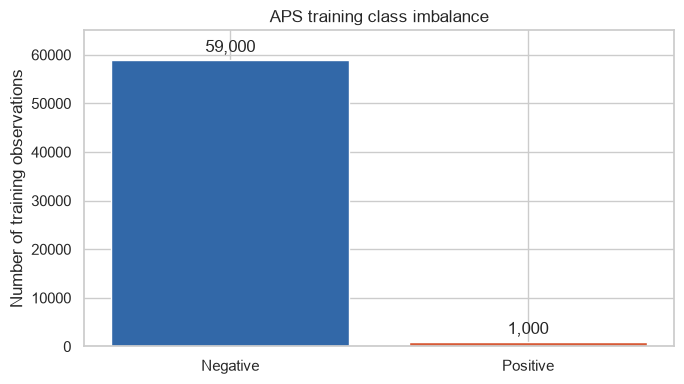

In [9]:
class_counts = pd.DataFrame({
    "training": train["class"].value_counts(),
    "test": test["class"].value_counts(),
}).reindex(["neg", "pos"]).T
class_counts["positive_percent"] = 100 * class_counts["pos"] / class_counts[["neg", "pos"]].sum(axis=1)
class_counts["negative_to_positive_ratio"] = class_counts["neg"] / class_counts["pos"]
display(class_counts.round(3))
assert class_counts.loc["training", "neg"] == 59000
assert class_counts.loc["training", "pos"] == 1000

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(["Negative", "Positive"], class_counts.loc["training", ["neg", "pos"]],
              color=[PALETTE["neg"], PALETTE["pos"]])
ax.bar_label(bars, fmt="{:,.0f}", padding=3)
ax.set_ylim(0, 65000)
ax.set_ylabel("Number of training observations")
ax.set_title("APS training class imbalance")
plt.tight_layout()
plt.show()

**Yes, the training data are severely imbalanced:** there are **59,000 negatives**
and **1,000 positives**, a **59:1** ratio. Positives account for only **1.667%** of the
training set. The test set has **15,625 negatives** and **375 positives** (2.344% positive).
Always predicting negative would achieve 98.333% training accuracy while detecting
no APS failures. Consequently, accuracy alone is inadequate; later classification
evaluation should include minority-class recall, precision, precision–recall AUC,
and the assignment's misclassification cost where required.

All 170 imputed features remain available in `X_train` and `X_test`, with binary labels
in `y_train` and `y_test`. The next section fits an unweighted random forest using these data. No SMOTE is
applied in parts (a)–(c).

### (c) Random forest without compensation for class imbalance
Train a standard random forest on **all 170 features** and the original training
labels. Use **300 trees**, Gini impurity, `max_features="sqrt"`, unrestricted tree
depth, bootstrap samples, and seed 42. These settings are fixed before examining
test results. There is **no class weighting, resampling, SMOTE, or threshold tuning**.
Numeric scaling is unnecessary for the tree splits.

The training-fitted median imputer from part (b) is reused. Class predictions use
the forest's default rule: select the class with the highest mean tree probability
(a 0.5 tie selects class 0). ROC curves and AUC use the probability of class 1 (`pos`),
not the hard predictions. Misclassification rate means $(FP+FN)/N$.

Reference: [scikit-learn RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html).

In [10]:
from time import perf_counter
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, confusion_matrix, roc_auc_score, roc_curve,
    precision_score, recall_score, ConfusionMatrixDisplay,
)

rf = RandomForestClassifier(
    n_estimators=300,
    criterion="gini",
    max_features="sqrt",
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    bootstrap=True,
    oob_score=True,
    class_weight=None,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
start = perf_counter()
rf.fit(X_train, y_train)
print(f"Fitted {len(rf.estimators_)} trees on {X_train.shape[0]:,} rows "
      f"and {rf.n_features_in_} features in {perf_counter() - start:.1f} seconds.")
assert rf.class_weight is None and rf.n_features_in_ == 170

Fitted 300 trees on 60,000 rows and 170 features in 32.9 seconds.


#### Training and test performance
Confusion matrices use **rows = actual class** and **columns = predicted class**, in
the order `neg`, `pos`: $\begin{pmatrix}TN & FP \\ FN & TP\end{pmatrix}$.
Training performance is measured on the fitting data and is optimistic. Test
performance is measured on the supplied, untouched test split. Precision and recall
are also reported to expose minority-class behavior behind the overall error rate.

In [11]:
rf_predictions = {}
rf_probabilities = {}
rf_confusion_matrices = {}
rf_roc_curves = {}
metric_rows = []
positive_column = int(np.flatnonzero(rf.classes_ == 1)[0])
for split, X, y in [("Training", X_train, y_train), ("Test", X_test, y_test)]:
    predicted = rf.predict(X)
    probability = rf.predict_proba(X)[:, positive_column]
    cm = confusion_matrix(y, predicted, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    rf_predictions[split] = predicted
    rf_probabilities[split] = probability
    rf_confusion_matrices[split] = cm
    rf_roc_curves[split] = roc_curve(y, probability, pos_label=1)
    metric_rows.append({
        "Split": split, "N": len(y), "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Misclassified": fp + fn,
        "Error (%)": 100 * (fp + fn) / len(y),
        "Accuracy (%)": 100 * accuracy_score(y, predicted),
        "ROC AUC": roc_auc_score(y, probability),
        "Positive precision": precision_score(y, predicted, zero_division=0),
        "Positive recall": recall_score(y, predicted, zero_division=0),
    })
    assert cm.sum() == len(y)
rf_results = pd.DataFrame(metric_rows).set_index("Split")
with pd.option_context("display.max_columns", None):
    display(rf_results.round(6))

,N,TN,FP,FN,TP,Misclassified,Error (%),Accuracy (%),ROC AUC,Positive precision,Positive recall
Split,,,,,,,,,,,
Training,60000,59000,0,0,1000,0,0.00000,100.00000,1.000000,1.000000,1.000000
Test,16000,15607,18,103,272,121,0.75625,99.24375,0.994226,0.937931,0.725333


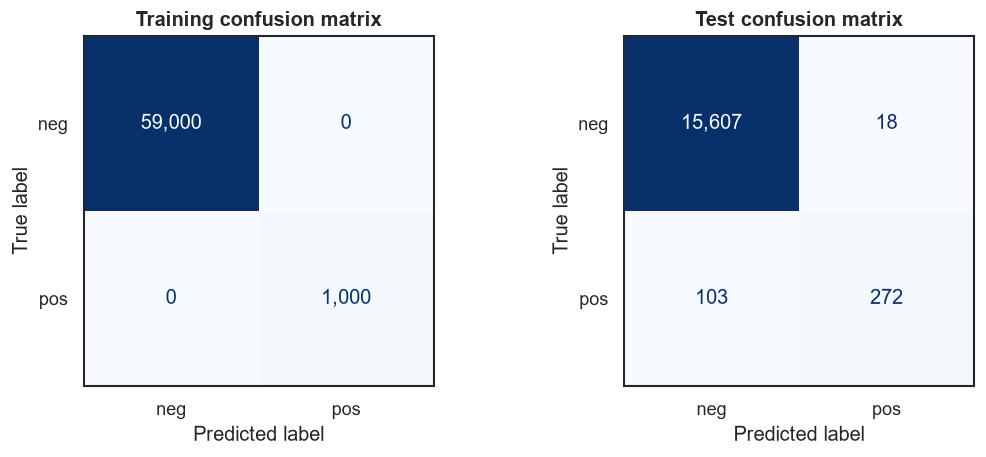

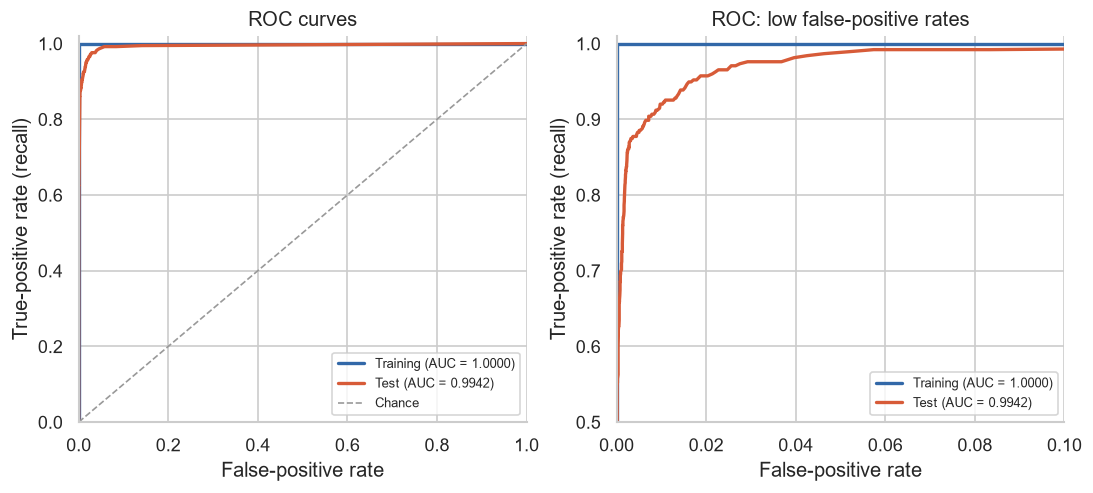

In [12]:
with sns.axes_style("white"), plt.rc_context({"figure.dpi": 120}):
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.7), layout="constrained")
    for ax, split in zip(axes, ["Training", "Test"]):
        ConfusionMatrixDisplay(
            rf_confusion_matrices[split], display_labels=["neg", "pos"]
        ).plot(ax=ax, cmap="Blues", colorbar=False, values_format=",d")
        ax.set_title(f"{split} confusion matrix", fontsize=12, fontweight="bold")
        ax.grid(False)
    plt.show()

with sns.axes_style("whitegrid"), plt.rc_context({"figure.dpi": 120}):
    fig, axes = plt.subplots(1, 2, figsize=(9, 4), layout="constrained")
    for split, color in [("Training", "#3268a8"), ("Test", "#d75b38")]:
        fpr, tpr, thresholds = rf_roc_curves[split]
        auc = rf_results.loc[split, "ROC AUC"]
        for ax in axes:
            ax.plot(fpr, tpr, color=color, linewidth=2,
                    label=f"{split} (AUC = {auc:.4f})")
    axes[0].plot([0, 1], [0, 1], "--", color="0.6", linewidth=1, label="Chance")
    axes[0].set(xlim=(0, 1), ylim=(0, 1.02), title="ROC curves")
    axes[1].set(xlim=(0, 0.1), ylim=(0.5, 1.01), title="ROC: low false-positive rates")
    for ax in axes:
        ax.set_xlabel("False-positive rate")
        ax.set_ylabel("True-positive rate (recall)")
        ax.legend(loc="lower right", fontsize=8)
    sns.despine(fig=fig)
    plt.show()

#### Out-of-bag error and comparison with test error
Each bootstrap tree leaves out roughly 36.8% of training observations. For each
observation, OOB prediction aggregates only the trees that did not use it. With the
default accuracy scorer, the forest's **OOB misclassification estimate is
`1 - rf.oob_score_`**. This is different from the in-sample training error.

This is the forest's OOB estimate conditional on the already imputed features:
the medians were learned from the whole training set, rather than separately for
each bootstrap sample. The test set played no role in imputation fitting or model fitting.

In [13]:
oob_probability = rf.oob_decision_function_
assert np.isfinite(oob_probability).all()
assert np.allclose(oob_probability.sum(axis=1), 1)
oob_predicted = rf.classes_[np.argmax(oob_probability, axis=1)]
oob_error = 1 - rf.oob_score_
assert np.isclose(oob_error, np.mean(oob_predicted != y_train.to_numpy()))
test_error = rf_results.loc["Test", "Error (%)"] / 100
rf_error_comparison = pd.DataFrame({
    "Misclassified": [rf_results.loc["Training", "Misclassified"],
                      int(np.sum(oob_predicted != y_train.to_numpy())),
                      rf_results.loc["Test", "Misclassified"]],
    "N": [len(y_train), len(y_train), len(y_test)],
    "Error (%)": [rf_results.loc["Training", "Error (%)"],
                  100 * oob_error, 100 * test_error],
}, index=["Training (in-sample)", "Training (out-of-bag)", "Test"])
display(rf_error_comparison.round(4))

gap_pp = 100 * (test_error - oob_error)
test_recall = rf_results.loc["Test", "Positive recall"]
test_fn = int(rf_results.loc["Test", "FN"])
test_tp = int(rf_results.loc["Test", "TP"])
display(Markdown(
    f"**Results.** Training error is **{rf_results.loc['Training', 'Error (%)']:.4f}%** "
    f"with AUC **{rf_results.loc['Training', 'ROC AUC']:.4f}**. "
    f"Test error is **{100 * test_error:.4f}%** with AUC "
    f"**{rf_results.loc['Test', 'ROC AUC']:.4f}**. "
    f"The OOB error is **{100 * oob_error:.4f}%**; test error minus OOB error is "
    f"**{gap_pp:+.4f} percentage points**. OOB therefore "
    f"{'underestimates' if gap_pp > 0 else 'overestimates' if gap_pp < 0 else 'matches'} "
    f"the observed test error. The two errors need not match: OOB evaluates the training "
    f"distribution using a subset of trees per observation, whereas test error uses the "
    f"full forest on a separate sample with a different positive prevalence.\n\n"
    f"At the default decision rule, the forest detects **{test_tp} of "
    f"{test_tp + test_fn}** positive test cases (recall **{100 * test_recall:.2f}%**) "
    f"and misses **{test_fn}**. Low aggregate error and high ROC AUC can coexist with "
    f"missed minority cases. The training results are optimistic; the test results "
    f"and OOB estimate are more informative about generalization."
))

,Misclassified,N,Error (%)
Training (in-sample),0,60000,0.0000
Training (out-of-bag),344,60000,0.5733
Test,121,16000,0.7562


**Results.** Training error is **0.0000%** with AUC **1.0000**. Test error is **0.7562%** with AUC **0.9942**. The OOB error is **0.5733%**; test error minus OOB error is **+0.1829 percentage points**. OOB therefore underestimates the observed test error. The two errors need not match: OOB evaluates the training distribution using a subset of trees per observation, whereas test error uses the full forest on a separate sample with a different positive prevalence.

At the default decision rule, the forest detects **272 of 375** positive test cases (recall **72.53%**) and misses **103**. Low aggregate error and high ROC AUC can coexist with missed minority cases. The training results are optimistic; the test results and OOB estimate are more informative about generalization.

### (d) Compensating for class imbalance in random forests
Three common approaches are:

1. **Class weighting:** give minority examples more weight when fitting trees.
   scikit-learn's `balanced` setting uses $w_k=N/(K n_k)$; `balanced_subsample`
   recomputes these weights within each tree's bootstrap sample.
2. **Balanced sampling:** construct class-balanced training samples for each tree.
   A balanced random forest samples the minority class and draws an equally sized
   majority sample. This increases minority representation but changes the data seen
   by each tree and can discard majority information within a tree.
3. **Oversampling, including SMOTE:** increase minority representation in training.
   Resampling must stay inside training folds during validation. A separately tuned
   decision threshold can also trade recall against false positives, but must be
   selected using training validation data, not the test set.

For this part I choose **`class_weight="balanced_subsample"`**. For the full training set,
the weights are $60000/(2\times59000)=0.508475$ for a negative example and
$60000/(2\times1000)=30$ for a positive example: each positive has **59 times** the
weight of a negative. These are reference weights: the actual weights are recomputed
for each bootstrap sample, giving the two classes equal total weight within each tree.
Weighting changes the fitting objective; it does not guarantee improved recall or AUC.

Clone the part (c) forest and change only `class_weight`, retaining its 300 trees,
seed, preprocessing, features, and default prediction rule. No SMOTE is used here.
This isolates weighting as the intervention and keeps the test split untouched.
Using `balanced_subsample` also keeps ordinary bootstrap draws in the installed
scikit-learn 1.9 implementation, allowing both classes to receive OOB predictions.

Sources: [scikit-learn random forest class weights](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)
and [imbalanced-learn balanced random forests](https://imbalanced-learn.org/stable/references/generated/imblearn.ensemble.BalancedRandomForestClassifier.html).

In [14]:
from sklearn.base import clone
from sklearn.utils.class_weight import compute_class_weight

classes = np.array([0, 1])
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
display(pd.DataFrame({"class": ["neg", "pos"], "weight": weights,
                      "training_count": [(y_train == k).sum() for k in classes]}))
weighted_rf = clone(rf).set_params(class_weight="balanced_subsample")
assert {k: v for k, v in weighted_rf.get_params().items() if k != "class_weight"} == {
    k: v for k, v in rf.get_params().items() if k != "class_weight"
}
start = perf_counter()
weighted_rf.fit(X_train, y_train)
print(f"Fitted class-weighted forest in {perf_counter() - start:.1f} seconds.")

,class,weight,training_count
0,neg,0.508475,59000
1,pos,30.000000,1000


Fitted class-weighted forest in 20.1 seconds.


#### Weighted-forest training and test metrics
Use the same confusion-matrix convention and probability-based ROC calculations
as part (c). All rates below are evaluated on the **original, unweighted observations**;
class weights affect fitting, not how errors are counted.

In [15]:
weighted_rf_predictions = {}
weighted_rf_probabilities = {}
weighted_rf_confusion_matrices = {}
weighted_rf_roc_curves = {}
metric_rows = []
positive_column = int(np.flatnonzero(weighted_rf.classes_ == 1)[0])
for split, X, y in [("Training", X_train, y_train), ("Test", X_test, y_test)]:
    predicted = weighted_rf.predict(X)
    probability = weighted_rf.predict_proba(X)[:, positive_column]
    cm = confusion_matrix(y, predicted, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    weighted_rf_predictions[split] = predicted
    weighted_rf_probabilities[split] = probability
    weighted_rf_confusion_matrices[split] = cm
    weighted_rf_roc_curves[split] = roc_curve(y, probability, pos_label=1)
    metric_rows.append({
        "Split": split, "N": len(y), "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Misclassified": fp + fn,
        "Error (%)": 100 * (fp + fn) / len(y),
        "Accuracy (%)": 100 * accuracy_score(y, predicted),
        "ROC AUC": roc_auc_score(y, probability),
        "Positive precision": precision_score(y, predicted, zero_division=0),
        "Positive recall": recall_score(y, predicted, zero_division=0),
    })
    assert cm.sum() == len(y)
weighted_rf_results = pd.DataFrame(metric_rows).set_index("Split")
with pd.option_context("display.max_columns", None):
    display(weighted_rf_results.round(6))

,N,TN,FP,FN,TP,Misclassified,Error (%),Accuracy (%),ROC AUC,Positive precision,Positive recall
Split,,,,,,,,,,,
Training,60000,59000,0,0,1000,0,0.0000,100.0000,1.000000,1.000000,1.000000
Test,16000,15608,17,161,214,178,1.1125,98.8875,0.993133,0.926407,0.570667


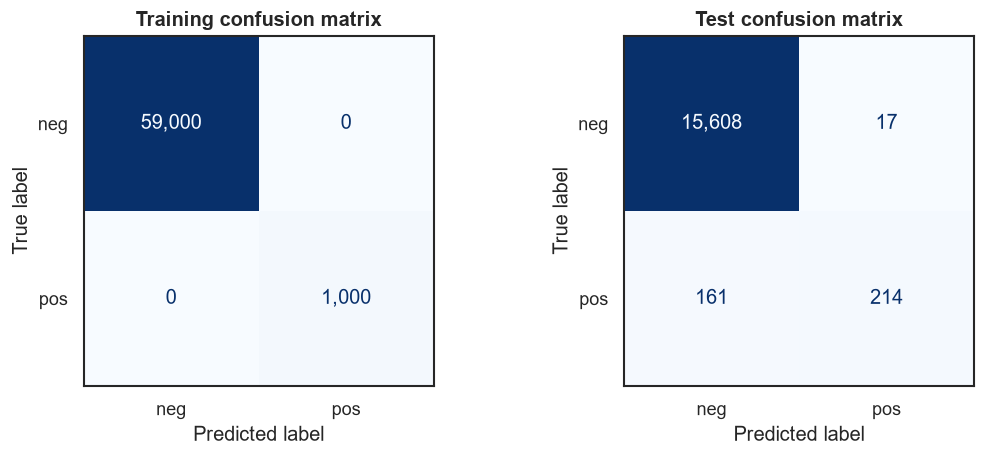

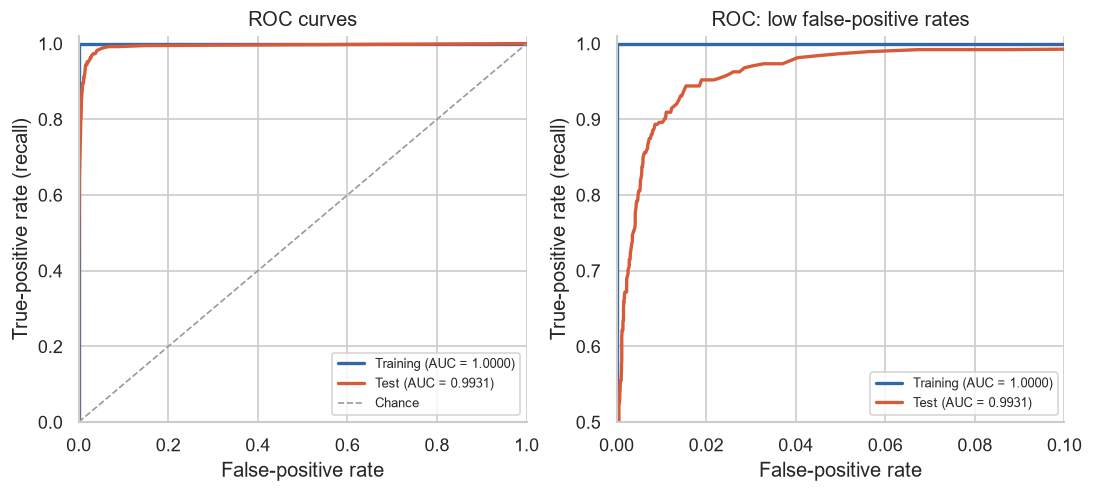

In [16]:
with sns.axes_style("white"), plt.rc_context({"figure.dpi": 120}):
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.7), layout="constrained")
    for ax, split in zip(axes, ["Training", "Test"]):
        ConfusionMatrixDisplay(
            weighted_rf_confusion_matrices[split], display_labels=["neg", "pos"]
        ).plot(ax=ax, cmap="Blues", colorbar=False, values_format=",d")
        ax.set_title(f"{split} confusion matrix", fontsize=12, fontweight="bold")
        ax.grid(False)
    plt.show()

with sns.axes_style("whitegrid"), plt.rc_context({"figure.dpi": 120}):
    fig, axes = plt.subplots(1, 2, figsize=(9, 4), layout="constrained")
    for split, color in [("Training", "#3268a8"), ("Test", "#d75b38")]:
        fpr, tpr, thresholds = weighted_rf_roc_curves[split]
        auc = weighted_rf_results.loc[split, "ROC AUC"]
        for ax in axes:
            ax.plot(fpr, tpr, color=color, linewidth=2,
                    label=f"{split} (AUC = {auc:.4f})")
    axes[0].plot([0, 1], [0, 1], "--", color="0.6", linewidth=1, label="Chance")
    axes[0].set(xlim=(0, 1), ylim=(0, 1.02), title="ROC curves")
    axes[1].set(xlim=(0, 0.1), ylim=(0.5, 1.01), title="ROC: low false-positive rates")
    for ax in axes:
        ax.set_xlabel("False-positive rate")
        ax.set_ylabel("True-positive rate (recall)")
        ax.legend(loc="lower right", fontsize=8)
    sns.despine(fig=fig)
    plt.show()

#### OOB error and direct comparison with part (c)
OOB error remains the ordinary fraction of misclassified training observations.
As in part (c), OOB predictions exclude each observation from the fitting samples
of the contributing trees, but preprocessing medians come from the full training set.

,Error (%)
Training (in-sample),0.0000
Training (out-of-bag),0.7567
Test,1.1125


Error (%)   ROC AUC  Positive precision  \
Model              Split                                               
Unweighted (c)     Training    0.00000  1.000000            1.000000   
                   Test        0.75625  0.994226            0.937931   
Class-weighted (d) Training    0.00000  1.000000            1.000000   
                   Test        1.11250  0.993133            0.926407   

                             Positive recall  FP   FN  
Model              Split                               
Unweighted (c)     Training         1.000000   0    0  
                   Test             0.725333  18  103  
Class-weighted (d) Training         1.000000   0    0  
                   Test             0.570667  17  161

,OOB error (%)
Unweighted (c),0.5733
Class-weighted (d),0.7567


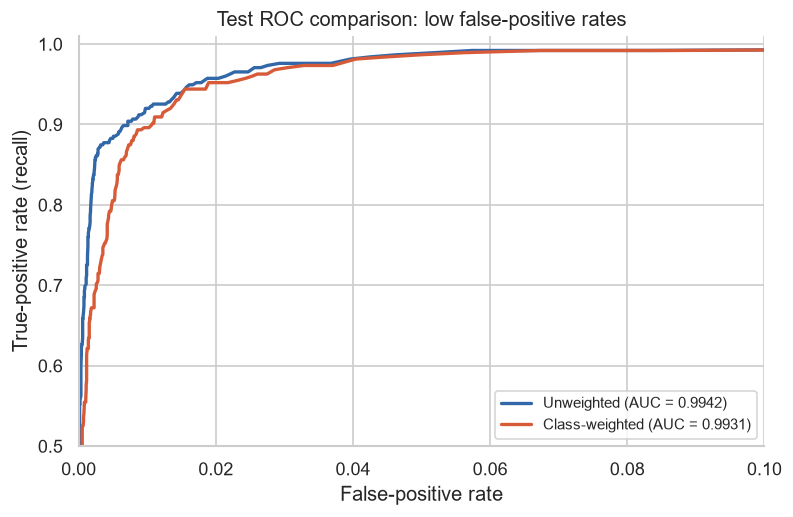

In [17]:
weighted_oob_prob = weighted_rf.oob_decision_function_
assert np.isfinite(weighted_oob_prob).all()
assert np.allclose(weighted_oob_prob.sum(axis=1), 1)
weighted_oob_pred = weighted_rf.classes_[weighted_oob_prob.argmax(axis=1)]
weighted_oob_error = 1 - weighted_rf.oob_score_
assert np.isclose(weighted_oob_error, np.mean(weighted_oob_pred != y_train.to_numpy()))
weighted_oob_comparison = pd.DataFrame({
    "Error (%)": [weighted_rf_results.loc["Training", "Error (%)"],
                  100 * weighted_oob_error, weighted_rf_results.loc["Test", "Error (%)"]],
}, index=["Training (in-sample)", "Training (out-of-bag)", "Test"])
display(weighted_oob_comparison.round(4))

forest_comparison = pd.concat({
    "Unweighted (c)": rf_results,
    "Class-weighted (d)": weighted_rf_results,
}, names=["Model", "Split"])
with pd.option_context("display.max_columns", None):
    display(forest_comparison[["Error (%)", "ROC AUC", "Positive precision",
                               "Positive recall", "FP", "FN"]].round(6))
display(pd.DataFrame({"OOB error (%)": [100 * oob_error, 100 * weighted_oob_error]},
                     index=["Unweighted (c)", "Class-weighted (d)"]).round(4))

with sns.axes_style("whitegrid"), plt.rc_context({"figure.dpi": 120}):
    fig, ax = plt.subplots(figsize=(6.5, 4.2), layout="constrained")
    for name, results, curves, color in [
        ("Unweighted", rf_results, rf_roc_curves, "#3268a8"),
        ("Class-weighted", weighted_rf_results, weighted_rf_roc_curves, "#d75b38"),
    ]:
        fpr, tpr, _ = curves["Test"]
        ax.plot(fpr, tpr, color=color, linewidth=2,
                label=f"{name} (AUC = {results.loc['Test', 'ROC AUC']:.4f})")
    ax.set(xlim=(0, 0.1), ylim=(0.5, 1.01), xlabel="False-positive rate",
           ylabel="True-positive rate (recall)", title="Test ROC comparison: low false-positive rates")
    ax.legend(loc="lower right", fontsize=9)
    sns.despine(ax=ax)
    plt.show()

In [18]:
baseline_test = rf_results.loc["Test"]
weighted_test = weighted_rf_results.loc["Test"]
recall_change_pp = 100 * (weighted_test["Positive recall"] - baseline_test["Positive recall"])
error_change_pp = weighted_test["Error (%)"] - baseline_test["Error (%)"]
auc_change = weighted_test["ROC AUC"] - baseline_test["ROC AUC"]
weighted_gap_pp = weighted_test["Error (%)"] - 100 * weighted_oob_error
display(Markdown(
    f"**Weighted-forest results.** Training error is "
    f"**{weighted_rf_results.loc['Training', 'Error (%)']:.4f}%**, with AUC "
    f"**{weighted_rf_results.loc['Training', 'ROC AUC']:.4f}**. Test error is "
    f"**{weighted_test['Error (%)']:.4f}%**, with AUC **{weighted_test['ROC AUC']:.4f}**. "
    f"OOB error is **{100 * weighted_oob_error:.4f}%**, so test error exceeds OOB error "
    f"by **{weighted_gap_pp:+.4f} percentage points**.\n\n"
    f"**Comparison with (c).** Weighting changes test error by **{error_change_pp:+.4f} "
    f"percentage points**, AUC by **{auc_change:+.4f}**, and positive recall by "
    f"**{recall_change_pp:+.2f} percentage points**. False negatives change from "
    f"**{int(baseline_test['FN'])} to {int(weighted_test['FN'])}**; false positives "
    f"change from **{int(baseline_test['FP'])} to {int(weighted_test['FP'])}**. "
    f"These observed changes, rather than the class-weight setting alone, determine "
    f"whether weighting helps on this test set.\n\n"
    f"Equal class weights in aggregate do not force equal class predictions or equal "
    f"recall. They can change splits and tree structure, and an unrestricted forest "
    f"can still favor the majority at its default decision rule. The test comparison "
    f"is descriptive: no hyperparameters or threshold were selected using test results."
))

**Weighted-forest results.** Training error is **0.0000%**, with AUC **1.0000**. Test error is **1.1125%**, with AUC **0.9931**. OOB error is **0.7567%**, so test error exceeds OOB error by **+0.3558 percentage points**.

**Comparison with (c).** Weighting changes test error by **+0.3563 percentage points**, AUC by **-0.0011**, and positive recall by **-15.47 percentage points**. False negatives change from **103 to 161**; false positives change from **18 to 17**. These observed changes, rather than the class-weight setting alone, determine whether weighting helps on this test set.

Equal class weights in aggregate do not force equal class predictions or equal recall. They can change splits and tree structure, and an unrestricted forest can still favor the majority at its default decision rule. The test comparison is descriptive: no hyperparameters or threshold were selected using test results.

### (e) XGBoost with L1 regularization, without imbalance compensation
**Instructor clarification.** In the instructor response supplied with this
assignment, Burak Barlas confirms that standard XGBoost with L1 regularization,
tuned using cross-validation, is sufficient for 1(e). A separate logistic regression
model tree is not required.

This implementation follows that clarification: use standard XGBoost trees with
`booster="gbtree"`, `objective="binary:logistic"`, and tune `reg_alpha`, the L1
regularization strength, using cross-validation.

Fix 150 boosting rounds, depth 3, learning rate 0.1, full row/column sampling,
`reg_lambda=0`, and `scale_pos_weight=1`. Tune only
$\alpha\in\{0.01,0.1,1,10\}$ by minimum validation misclassification rate.
No weighting or resampling compensates for imbalance in (e).

**Validation design.** Use stratified **five-fold nested cross-validation** on the
60,000 training rows. Each outer fold is held out from every preprocessing and
tuning step; an inner five-fold search chooses alpha from that outer training fold.
The outer-fold predictions estimate the error of the tuning procedure. Separately,
run a five-fold search on all training data to select the final alpha and refit the
model. The best inner score is a tuning score, not the independent error estimate.
The supplied test split is used only for final reporting.

Both (e) and (f) use training-fitted median imputation, `log1p`, and standardization
inside their pipelines. Every feature is nonnegative. The log transformation
reduces heavy tails; scaling makes distance-based SMOTE meaningful in (f). The same
preprocessing in (e) controls this difference. All 170 features are retained.

Reference: [XGBoost parameters](https://xgboost.readthedocs.io/en/stable/parameter.html).

In [19]:
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

ALPHA_GRID = [0.01, 0.1, 1.0, 10.0]
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
outer_splits = list(outer_cv.split(X_train_raw, y_train))
assert (X_train_raw.min() >= 0).all()

def make_xgb_pipeline(use_smote=False):
    steps = [
        ("imputer", SimpleImputer(strategy="median")),
        ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("scaler", StandardScaler()),
    ]
    if use_smote:
        steps.append(("smote", SMOTE(sampling_strategy="auto", k_neighbors=5,
                                     random_state=RANDOM_STATE)))
    steps.append(("model", XGBClassifier(
        booster="gbtree", objective="binary:logistic", eval_metric="logloss",
        n_estimators=150, max_depth=3, learning_rate=0.1,
        subsample=1.0, colsample_bytree=1.0, reg_lambda=0.0,
        scale_pos_weight=1.0, tree_method="hist", n_jobs=2,
        random_state=RANDOM_STATE,
    )))
    return ImbPipeline(steps)

def xgb_alpha_search(use_smote, seed):
    inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    return GridSearchCV(
        make_xgb_pipeline(use_smote), {"model__reg_alpha": ALPHA_GRID},
        scoring="accuracy", cv=inner_cv, refit=True,
        n_jobs=2, pre_dispatch=2, error_score="raise", return_train_score=False,
    )

def nested_xgb_experiment(use_smote):
    name = "SMOTE XGBoost" if use_smote else "Uncompensated XGBoost"
    oof_pred = np.full(len(y_train), -1, dtype=int)
    oof_prob = np.full(len(y_train), np.nan)
    fold_rows = []
    start = perf_counter()
    for fold, (fit_idx, val_idx) in enumerate(outer_splits, start=1):
        search = xgb_alpha_search(use_smote, RANDOM_STATE + fold)
        search.fit(X_train_raw.iloc[fit_idx], y_train.iloc[fit_idx])
        predicted = search.predict(X_train_raw.iloc[val_idx])
        probability = search.predict_proba(X_train_raw.iloc[val_idx])[:, 1]
        oof_pred[val_idx] = predicted
        oof_prob[val_idx] = probability
        row = {
            "Outer fold": fold,
            "Selected alpha": search.best_params_["model__reg_alpha"],
            "Validation N": len(val_idx),
            "Outer error (%)": 100 * np.mean(predicted != y_train.iloc[val_idx]),
            "Outer ROC AUC": roc_auc_score(y_train.iloc[val_idx], probability),
        }
        fold_rows.append(row)
        print(f"{name}: outer fold {fold}/5 finished; "
              f"alpha={row['Selected alpha']:g}, error={row['Outer error (%)']:.4f}%",
              flush=True)
    assert np.all(oof_pred >= 0) and np.isfinite(oof_prob).all()
    final_search = xgb_alpha_search(use_smote, RANDOM_STATE)
    final_search.fit(X_train_raw, y_train)
    folds = pd.DataFrame(fold_rows).set_index("Outer fold")
    tuning = pd.DataFrame(final_search.cv_results_)
    tuning_table = pd.DataFrame({
        "alpha": tuning["param_model__reg_alpha"].astype(float),
        "Mean tuning error (%)": 100 * (1 - tuning["mean_test_score"]),
        "Fold SD (percentage points)": 100 * tuning["std_test_score"],
        "Rank": tuning["rank_test_score"],
    }).sort_values("alpha")
    print(f"{name}: final alpha={final_search.best_params_['model__reg_alpha']:g}; "
          f"elapsed {perf_counter() - start:.1f} seconds.", flush=True)
    return {
        "search": final_search, "model": final_search.best_estimator_,
        "folds": folds, "tuning": tuning_table,
        "oof_predictions": oof_pred, "oof_probabilities": oof_prob,
        "nested_error": np.mean(oof_pred != y_train.to_numpy()),
    }

def report_xgb(experiment, title):
    model = experiment["model"]
    rows, matrices, curves = [], {}, {}
    for split, X, y in [("Training", X_train_raw, y_train), ("Test", X_test_raw, y_test)]:
        predicted = model.predict(X)
        probability = model.predict_proba(X)[:, 1]
        cm = confusion_matrix(y, predicted, labels=[0, 1])
        tn, fp, fn, tp = cm.ravel()
        matrices[split] = cm
        curves[split] = roc_curve(y, probability)
        rows.append({
            "Split": split, "N": len(y), "TN": tn, "FP": fp, "FN": fn, "TP": tp,
            "Misclassified": fp + fn, "Error (%)": 100 * (fp + fn) / len(y),
            "ROC AUC": roc_auc_score(y, probability),
            "Positive precision": precision_score(y, predicted, zero_division=0),
            "Positive recall": recall_score(y, predicted, zero_division=0),
        })
        assert cm.sum() == len(y)
    results = pd.DataFrame(rows).set_index("Split")
    display(experiment["folds"].round(6))
    display(experiment["tuning"].round(6))
    with pd.option_context("display.max_columns", None):
        display(results.round(6))
    with sns.axes_style("white"), plt.rc_context({"figure.dpi": 120}):
        fig, axes = plt.subplots(1, 2, figsize=(9, 3.7), layout="constrained")
        for ax, split in zip(axes, ["Training", "Test"]):
            ConfusionMatrixDisplay(matrices[split], display_labels=["neg", "pos"]).plot(
                ax=ax, cmap="Blues", colorbar=False, values_format=",d")
            ax.set_title(f"{split} confusion matrix", fontsize=12, fontweight="bold")
            ax.grid(False)
        fig.suptitle(title, fontsize=13)
        plt.show()
    with sns.axes_style("whitegrid"), plt.rc_context({"figure.dpi": 120}):
        fig, axes = plt.subplots(1, 2, figsize=(9, 4), layout="constrained")
        for split, color in [("Training", "#3268a8"), ("Test", "#d75b38")]:
            fpr, tpr, _ = curves[split]
            for ax in axes:
                ax.plot(fpr, tpr, color=color, linewidth=2,
                        label=f"{split} (AUC = {results.loc[split, 'ROC AUC']:.4f})")
        axes[0].plot([0, 1], [0, 1], "--", color="0.6", linewidth=1)
        axes[0].set(xlim=(0, 1), ylim=(0, 1.02), title="ROC curves")
        axes[1].set(xlim=(0, 0.1), ylim=(0.5, 1.01), title="ROC: low false-positive rates")
        for ax in axes:
            ax.set_xlabel("False-positive rate")
            ax.set_ylabel("True-positive rate (recall)")
            ax.legend(loc="lower right", fontsize=8)
        sns.despine(fig=fig)
        plt.show()
    nested_pct = 100 * experiment["nested_error"]
    sd = experiment["folds"]["Outer error (%)"].std(ddof=1)
    test_pct = results.loc["Test", "Error (%)"]
    display(Markdown(
        f"**Selected alpha:** {experiment['search'].best_params_['model__reg_alpha']:g}. "
        f"The nested five-fold error estimate is **{nested_pct:.4f}%**, with outer-fold "
        f"SD **{sd:.4f} percentage points** (descriptive spread, not a confidence interval). "
        f"The final model's test error is **{test_pct:.4f}%**, a difference of "
        f"**{test_pct - nested_pct:+.4f} percentage points** relative to nested CV. "
        f"Nested CV evaluates models fitted on 80% of training rows; the final model "
        f"uses all training rows. Sampling and differing class prevalence can also "
        f"make the two errors differ."
    ))
    experiment.update(results=results, matrices=matrices, curves=curves)
    return results

In [ ]:
xgb_plain = nested_xgb_experiment(use_smote=False)
xgb_plain_results = report_xgb(xgb_plain, "(e) XGBoost without imbalance compensation")

Uncompensated XGBoost: outer fold 1/5 finished; alpha=0.1, error=0.5500%
Uncompensated XGBoost: outer fold 2/5 finished; alpha=0.01, error=0.6833%
Uncompensated XGBoost: outer fold 3/5 finished; alpha=0.1, error=0.6750%
Uncompensated XGBoost: outer fold 4/5 finished; alpha=1, error=0.6417%


### (f) SMOTE followed by L1-regularized XGBoost
Use the same feature set, preprocessing, tree settings, alpha grid, outer splits,
and nested five-fold protocol as in (e). Insert **SMOTE after imputation, `log1p`,
and scaling**, using five minority neighbors and seed 42. SMOTE balances the
training classes by synthesizing minority observations in this transformed feature
space; it does not add observations to validation or test data.

**Correct order within every inner and outer training fold:** fit imputer and scaler
on that fold's fitting rows, transform them, fit/resample SMOTE on those transformed
fitting rows only, then train XGBoost. Predict held-out rows using the fitted
transformations, with **no resampling at prediction time**. An imbalanced-learn
pipeline enforces this order inside `GridSearchCV`. Resampling the full training
set before cross-validation would leak information and produce a misleading error
estimate. Only after selection is the final pipeline fitted, with SMOTE, on all
60,000 training rows. Evaluate its training metrics on the original 60,000 rows and
its test metrics on the original 16,000 rows, not on synthetic or balanced test data.

Source: [imbalanced-learn: resampling leakage and pipelines](https://imbalanced-learn.org/stable/common_pitfalls.html).
Use the same standard, L1-regularized XGBoost model as in (e), consistent
with the instructor clarification; add SMOTE only within fitting folds.

SMOTE XGBoost: outer fold 1/5 finished; alpha=0.1, error=1.7917%


SMOTE XGBoost: outer fold 2/5 finished; alpha=0.1, error=1.7250%


SMOTE XGBoost: outer fold 3/5 finished; alpha=0.1, error=1.7583%


SMOTE XGBoost: outer fold 4/5 finished; alpha=0.1, error=1.7833%


SMOTE XGBoost: outer fold 5/5 finished; alpha=0.1, error=1.5167%


SMOTE XGBoost: final alpha=1; elapsed 340.8 seconds.


,Selected alpha,Validation N,Outer error (%),Outer ROC AUC
Outer fold,,,,
1,0.1,12000,1.791667,0.994592
2,0.1,12000,1.725000,0.986082
3,0.1,12000,1.758333,0.987762
4,0.1,12000,1.783333,0.979314
5,0.1,12000,1.516667,0.978459


,alpha,Mean tuning error (%),Fold SD (percentage points),Rank
0,0.01,1.710000,0.089969,2
1,0.10,1.715000,0.101844,3
2,1.00,1.695000,0.141676,1
3,10.00,1.746667,0.119559,4


,N,TN,FP,FN,TP,Misclassified,Error (%),ROC AUC,Positive precision,Positive recall
Split,,,,,,,,,,
Training,60000,58194,806,47,953,853,1.421667,0.996279,0.541785,0.953000
Test,16000,15401,224,35,340,259,1.618750,0.993958,0.602837,0.906667


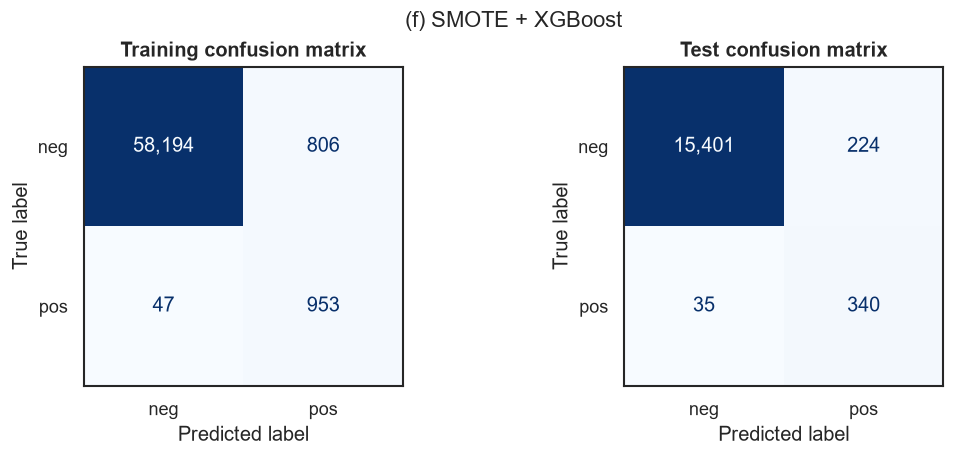

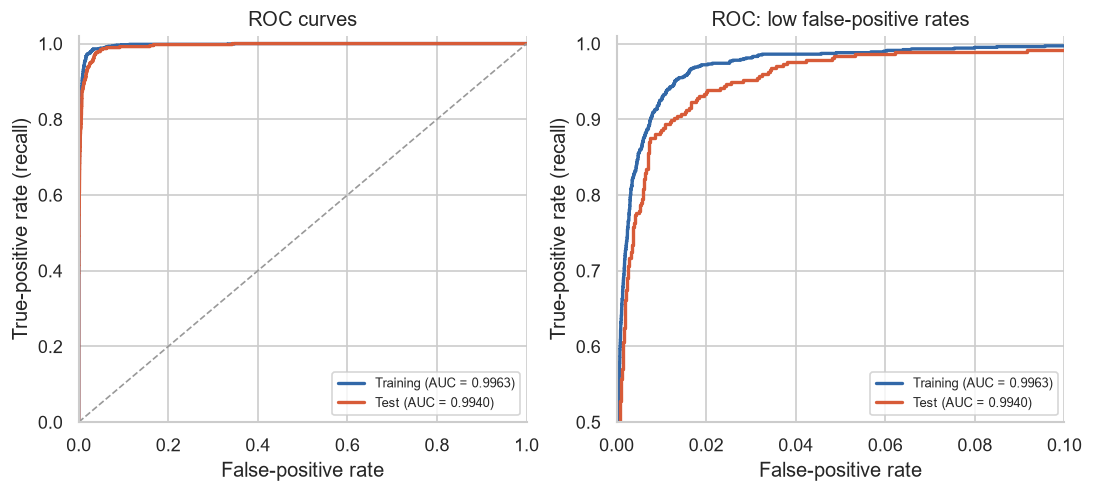

**Selected alpha:** 1. The nested five-fold error estimate is **1.7150%**, with outer-fold SD **0.1139 percentage points** (descriptive spread, not a confidence interval). The final model's test error is **1.6187%**, a difference of **-0.0962 percentage points** relative to nested CV. Nested CV evaluates models fitted on 80% of training rows; the final model uses all training rows. Sampling and differing class prevalence can also make the two errors differ.

,Original training count,Synthetic count,Resampled training count
class,,,
neg,59000,0,59000
pos,1000,58000,59000


In [ ]:
xgb_smote = nested_xgb_experiment(use_smote=True)
xgb_smote_results = report_xgb(xgb_smote, "(f) SMOTE + XGBoost")
synthetic_counts = xgb_smote["model"].named_steps["smote"].sampling_strategy_
original_counts = y_train.value_counts().sort_index()
display(pd.DataFrame({
    "Original training count": original_counts,
    "Synthetic count": [synthetic_counts.get(k, 0) for k in original_counts.index],
    "Resampled training count": [original_counts[k] + synthetic_counts.get(k, 0)
                                 for k in original_counts.index],
}).rename(index={0: "neg", 1: "pos"}))

#### Compare uncompensated XGBoost with SMOTE
Use the original class distribution for all reported errors. Alpha is selected
independently for each pipeline using training data; nested validation includes
this selection step. Compare recall and false positives as well as aggregate error
and AUC, since improving minority recall can increase the total number of errors.

Error (%)   ROC AUC  Positive precision  \
Model             Split                                               
Uncompensated (e) Training   0.361667  0.998050            0.947429   
                  Test       0.825000  0.995631            0.923345   
SMOTE (f)         Training   1.421667  0.996279            0.541785   
                  Test       1.618750  0.993958            0.602837   

                            Positive recall   FP   FN  
Model             Split                                
Uncompensated (e) Training         0.829000   46  171  
                  Test             0.706667   22  110  
SMOTE (f)         Training         0.953000  806   47  
                  Test             0.906667  224   35

,Final alpha,Nested CV error (%),Test error (%)
Uncompensated (e),0.01,0.646667,0.82500
SMOTE (f),1.00,1.715000,1.61875


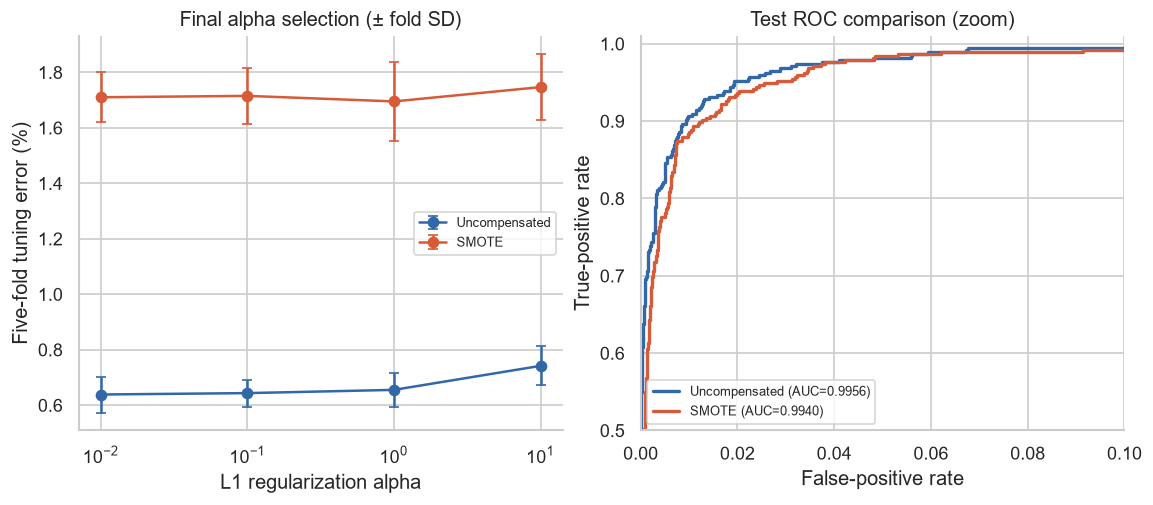

**Effect of SMOTE.** Test recall changes from **70.67%** to **90.67%**; false negatives change from **110 to 35** and false positives from **22 to 224**. Test error changes from **0.8250% to 1.6187%**, and ROC AUC changes from **0.9956 to 0.9940**. Thus the benefit depends on the relative importance of missed APS failures and unnecessary inspections, rather than accuracy alone.

SMOTE changes the fitting distribution; its predicted probabilities need not be calibrated to the original rare-positive prevalence. Both models use the default 0.5 decision threshold, with no test-based threshold selection. Synthetic points are interpolations, not additional observed failures, and may be imperfect in this high-dimensional dataset.

In [ ]:
xgb_comparison = pd.concat({"Uncompensated (e)": xgb_plain_results,
                            "SMOTE (f)": xgb_smote_results}, names=["Model", "Split"])
with pd.option_context("display.max_columns", None):
    display(xgb_comparison[["Error (%)", "ROC AUC", "Positive precision",
                            "Positive recall", "FP", "FN"]].round(6))
display(pd.DataFrame({
    "Final alpha": [exp["search"].best_params_["model__reg_alpha"]
                    for exp in [xgb_plain, xgb_smote]],
    "Nested CV error (%)": [100 * exp["nested_error"] for exp in [xgb_plain, xgb_smote]],
    "Test error (%)": [exp["results"].loc["Test", "Error (%)"]
                       for exp in [xgb_plain, xgb_smote]],
}, index=["Uncompensated (e)", "SMOTE (f)"]).round(6))

with sns.axes_style("whitegrid"), plt.rc_context({"figure.dpi": 120}):
    fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.1), layout="constrained")
    for name, exp, color in [("Uncompensated", xgb_plain, "#3268a8"),
                              ("SMOTE", xgb_smote, "#d75b38")]:
        tune = exp["tuning"]
        axes[0].errorbar(tune["alpha"], tune["Mean tuning error (%)"],
                         yerr=tune["Fold SD (percentage points)"],
                         marker="o", capsize=3, color=color, label=name)
        fpr, tpr, _ = exp["curves"]["Test"]
        axes[1].plot(fpr, tpr, color=color, linewidth=2,
                     label=f"{name} (AUC={exp['results'].loc['Test', 'ROC AUC']:.4f})")
    axes[0].set(xscale="log", xlabel="L1 regularization alpha",
                ylabel="Five-fold tuning error (%)", title="Final alpha selection (± fold SD)")
    axes[1].set(xlim=(0, 0.1), ylim=(0.5, 1.01), xlabel="False-positive rate",
                ylabel="True-positive rate", title="Test ROC comparison (zoom)")
    for ax in axes:
        ax.legend(fontsize=8)
    sns.despine(fig=fig)
    plt.show()

plain_test = xgb_plain_results.loc["Test"]
smote_test = xgb_smote_results.loc["Test"]
display(Markdown(
    f"**Effect of SMOTE.** Test recall changes from "
    f"**{100 * plain_test['Positive recall']:.2f}%** to "
    f"**{100 * smote_test['Positive recall']:.2f}%**; false negatives change from "
    f"**{int(plain_test['FN'])} to {int(smote_test['FN'])}** and false positives from "
    f"**{int(plain_test['FP'])} to {int(smote_test['FP'])}**. Test error changes from "
    f"**{plain_test['Error (%)']:.4f}% to {smote_test['Error (%)']:.4f}%**, and ROC AUC "
    f"changes from **{plain_test['ROC AUC']:.4f} to {smote_test['ROC AUC']:.4f}**. "
    f"Thus the benefit depends on the relative importance of missed APS failures and "
    f"unnecessary inspections, rather than accuracy alone.\n\n"
    f"SMOTE changes the fitting distribution; its predicted probabilities need not be "
    f"calibrated to the original rare-positive prevalence. Both models use the default "
    f"0.5 decision threshold, with no test-based threshold selection. Synthetic points "
    f"are interpolations, not additional observed failures, and may be imperfect in "
    f"this high-dimensional dataset."
))

## 2. Lasso Regularization and the Bias–Variance Trade-off

The regression coefficients are estimated by minimizing

$$
\sum_{i=1}^{n}\left(y_i-\beta_0-\sum_{j=1}^{p}\beta_jx_{ij}\right)^2
\quad\text{subject to}\quad
\sum_{j=1}^{p}|\beta_j|\leq s.
$$

This is the constrained form of **lasso regression**. When $s=0$, all slope
coefficients must be zero, so the fitted model only has an intercept. Increasing
$s$ relaxes the constraint, allowing a more flexible model with less shrinkage.
Thus, increasing $s$ has the opposite effect of increasing the penalty parameter
$\lambda$ in the penalized form of lasso.

### (a) Training RSS: iv. Steadily decrease

As $s$ increases, the set of allowed coefficient values becomes larger. Any solution
that was allowed for a smaller $s$ is still allowed for a larger $s$, so the minimum
training RSS cannot increase. Therefore, I choose **iv**. More precisely, training
RSS is **non-increasing**: it can stay unchanged over some intervals and becomes
constant once the constraint is loose enough to attain the unconstrained least-squares RSS.

### (b) Test RSS: ii. Decrease initially, then increase in a U shape

At a small $s$, the model is strongly constrained and can underfit. Increasing $s$
initially lets it capture more of the relationship between the predictors and the
response, reducing test RSS. If $s$ becomes too large, the model may also fit noise
in the training data, increasing test RSS. Therefore, the usual expected pattern is
a **U shape**, so I choose **ii**. This is the general bias–variance pattern, rather
than a guarantee of an exact U shape for every dataset.

### (c) Variance: iii. Steadily increase

With a larger $s$, the coefficients are less constrained and the fitted model is
more sensitive to changes in the training sample. Its variance therefore generally
increases as flexibility increases. I choose **iii**.

### (d) Squared bias: iv. Steadily decrease

A small $s$ forces strong shrinkage, which can prevent the model from capturing the
underlying relationship. As $s$ increases, this restriction becomes weaker and the
model can fit that relationship more closely. Squared bias therefore generally
decreases. I choose **iv**.

### (e) Irreducible error: v. Remain constant

The irreducible error comes from the noise in the data-generating process. Changing
$s$ changes the fitted model, but it does not change this noise variance,
$\sigma^2$. Therefore, I choose **v**.

These answers follow the usual decomposition

$$
\mathbb{E}\!\left[(Y_0-\hat f_s(x_0))^2\right]
=\operatorname{Bias}\!\left[\hat f_s(x_0)\right]^2
+\operatorname{Var}\!\left[\hat f_s(x_0)\right]
+\sigma^2.
$$

Increasing $s$ generally reduces squared bias and increases variance, while the
irreducible error stays fixed. The balance between bias and variance explains the
expected U-shaped test error.


## 3. Ridge and Lasso with Identical Predictors

Here, $n=p=2$, the two predictor columns are identical, and the response and
predictors are centered. Therefore, $\hat\beta_0=0$. I write

$$
a=x_{11}=x_{12},\qquad x_{21}=x_{22}=-a,
\qquad b=y_1,\quad y_2=-b.
$$

The fitted values depend only on the sum $\beta_1+\beta_2$. I assume $\lambda>0$
for the penalized fits below.

### (a) Ridge regression optimization problem

The ridge estimates minimize

$$
\min_{\beta_1,\beta_2}
\left\{
(y_1-\beta_1x_{11}-\beta_2x_{12})^2
+(y_2-\beta_1x_{21}-\beta_2x_{22})^2
+\lambda(\beta_1^2+\beta_2^2)
\right\}.
$$

Using the equalities above, this becomes

$$
\boxed{\min_{\beta_1,\beta_2}
\left\{2\big[b-a(\beta_1+\beta_2)\big]^2
+\lambda(\beta_1^2+\beta_2^2)\right\}.}
$$

### (b) Why the ridge estimates are equal

Differentiating the ridge objective with respect to the two coefficients gives

$$
-4a\big[b-a(\beta_1+\beta_2)\big]+2\lambda\beta_1=0,
$$

$$
-4a\big[b-a(\beta_1+\beta_2)\big]+2\lambda\beta_2=0.
$$

Subtracting these equations gives

$$
2\lambda(\beta_1-\beta_2)=0.
$$

Since $\lambda>0$, this implies

$$
\boxed{\hat\beta_1=\hat\beta_2.}
$$

Substituting the common value into either equation also gives

$$
\hat\beta_1=\hat\beta_2=\frac{2ab}{4a^2+\lambda}.
$$

Another way to see this is to fix the sum $z=\beta_1+\beta_2$. The RSS is then
fixed, while

$$
\beta_1^2+\beta_2^2
=\frac{z^2+(\beta_1-\beta_2)^2}{2}
$$

is smallest when $\beta_1=\beta_2=z/2$. Ridge therefore divides the coefficient
equally between the identical predictors. If $\lambda=0$, this uniqueness argument
does not apply: ordinary least squares can have unequal coefficients with the same sum.

### (c) Lasso optimization problem

The lasso estimates minimize

$$
\min_{\beta_1,\beta_2}
\left\{
(y_1-\beta_1x_{11}-\beta_2x_{12})^2
+(y_2-\beta_1x_{21}-\beta_2x_{22})^2
+\lambda\big(|\beta_1|+|\beta_2|\big)
\right\}.
$$

Equivalently,

$$
\boxed{\min_{\beta_1,\beta_2}
\left\{2\big[b-a(\beta_1+\beta_2)\big]^2
+\lambda\big(|\beta_1|+|\beta_2|\big)\right\}.}
$$

### (d) Why lasso can have many solutions

Let $z=\beta_1+\beta_2$. For a fixed $z$, every coefficient pair has the same RSS.
By the triangle inequality,

$$
|\beta_1|+|\beta_2|\geq|\beta_1+\beta_2|=|z|.
$$

Equality holds whenever the coefficients have the same sign, allowing either one
to be zero. Therefore, the lasso problem reduces to

$$
\min_z\left\{2(b-az)^2+\lambda|z|\right\}.
$$

If the optimal sum is $\hat z\ne0$, **all** the following pairs minimize the
original lasso objective:

$$
\boxed{(\hat\beta_1,\hat\beta_2)
=\big(t\hat z,(1-t)\hat z\big),\qquad 0\leq t\leq1.}
$$

For example, $(\hat z,0)$, $(0,\hat z)$, and $(\hat z/2,\hat z/2)$ have the same
fitted values and the same L1 penalty. The solutions form the line segment between
$(\hat z,0)$ and $(0,\hat z)$. Lasso can therefore put all the effect on one
predictor or split it between the two, unlike ridge's unique equal split.

For completeness, when $a\ne0$, minimizing the one-variable objective gives

$$
\hat z=
\begin{cases}
\dfrac{4ab-\lambda}{4a^2}, & 4ab>\lambda,\\[6pt]
0, & |4ab|\leq\lambda,\\[6pt]
\dfrac{4ab+\lambda}{4a^2}, & 4ab<-\lambda.
\end{cases}
$$

**Zero-solution exception:** if the penalty is large enough that $\hat z=0$, then
for $\lambda>0$ the only optimal pair is $(0,0)$. Thus the non-uniqueness described
above applies when the optimal sum is nonzero. If $a=0$, both predictor columns
are zero, and a positive penalty also gives $(0,0)$.


## 4. Majority Vote vs. Average Probability

The ten estimates of $P(\text{Red}\mid X)$ are

$$
0.10,\ 0.15,\ 0.20,\ 0.20,\ 0.55,\ 0.60,\ 0.60,\ 0.65,\ 0.70,\ 0.75.
$$

### Majority vote

Each tree predicts Red if its estimated probability of Red is greater than $0.5$,
and Green if it is less than $0.5$.

- **Red:** $0.55, 0.60, 0.60, 0.65, 0.70, 0.75$, giving **6 votes**.
- **Green:** $0.10, 0.15, 0.20, 0.20$, giving **4 votes**.

Since Red receives more votes, the majority-vote classification is **Red**.

### Average probability

First, I average the ten estimated probabilities:

$$
\bar p_{\text{Red}}
=\frac{0.10+0.15+0.20+0.20+0.55+0.60+0.60+0.65+0.70+0.75}{10}
=\frac{4.50}{10}
=0.45.
$$

The average probability of Green is $1-0.45=0.55$. Since $0.45<0.5$, the
average-probability classification is **Green**.

The two methods disagree because majority voting gives each tree one vote,
regardless of its probability estimate. Averaging probabilities also accounts for
how strongly each tree favors a class. Here, the four trees favoring Green have
low Red probabilities, which pull the overall average below $0.5$ despite Red
receiving more individual votes.


## 5. Maximal Margin Classifier

I first plot the seven observations. The other panels show the optimal separating
line and its margins, a separating line with a smaller margin, and an additional
Blue observation that makes the classes nonseparable. The numbers identify the
observations in the question.

,X1,X2,Class
Observation,,,
1,3,4,Red
2,2,2,Red
3,4,4,Red
4,1,4,Red
5,2,1,Blue
6,4,3,Blue
7,4,1,Blue


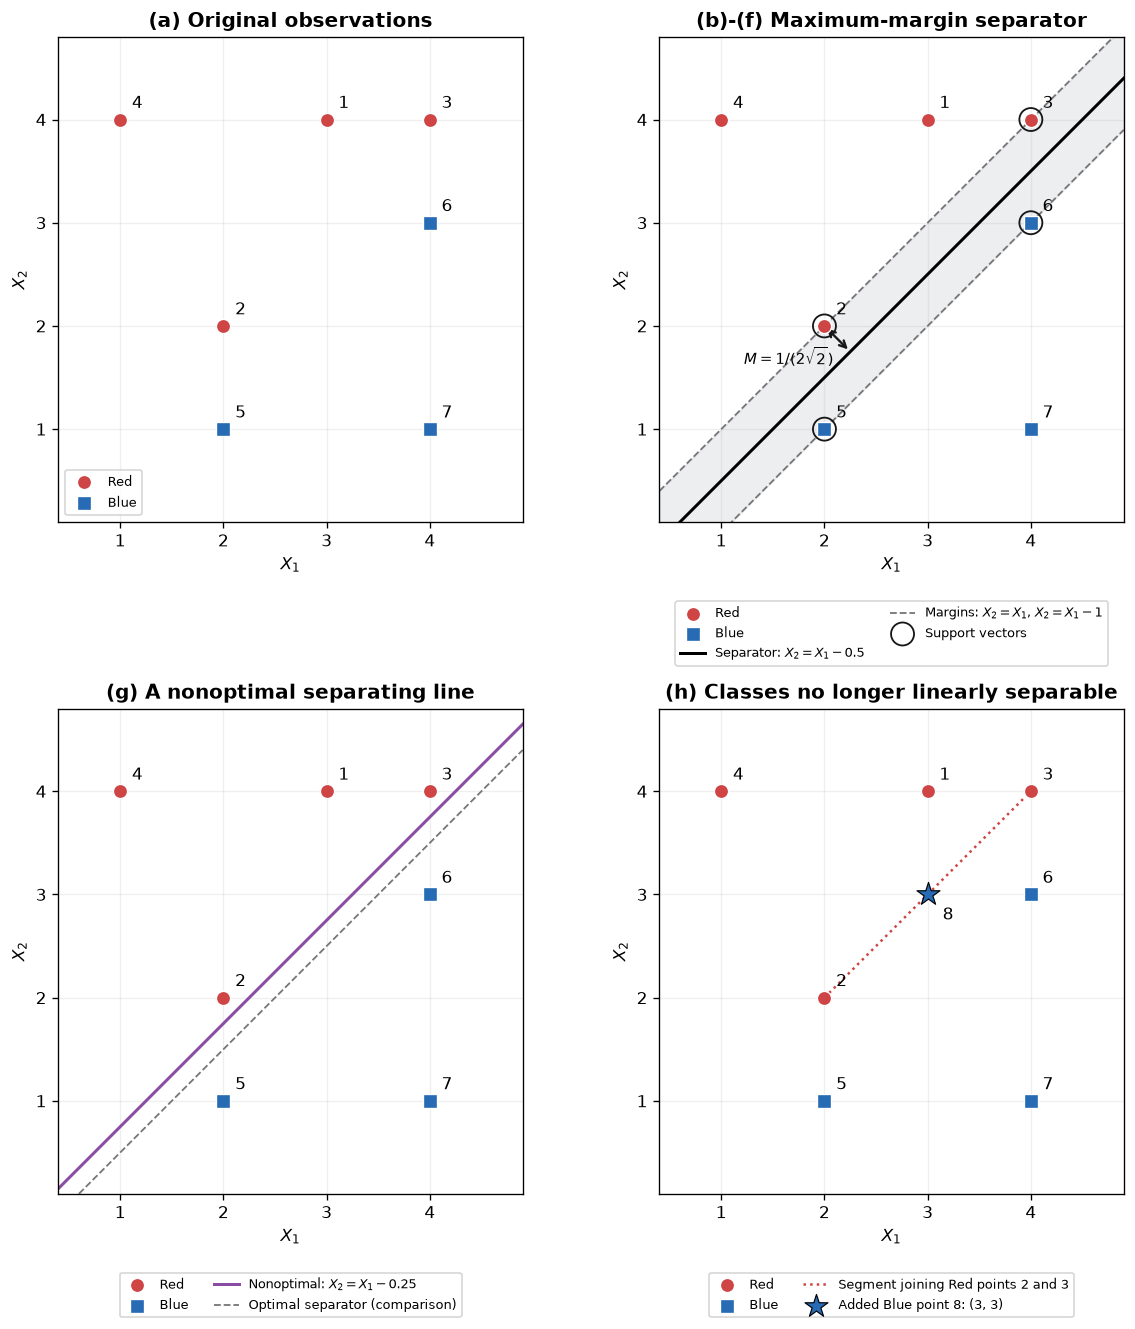

Margin on each side: 0.353553
Total width between margin lines: 0.707107
Support-vector observations: [2, 3, 5, 6]


In [ ]:
toy = pd.DataFrame({
    "X1": [3, 2, 4, 1, 2, 4, 4],
    "X2": [4, 2, 4, 4, 1, 3, 1],
    "Class": ["Red", "Red", "Red", "Red", "Blue", "Blue", "Blue"],
}, index=pd.Index(range(1, 8), name="Observation"))
display(toy)

toy_score = 0.5 - toy["X1"] + toy["X2"]
toy_y = np.where(toy["Class"].eq("Red"), 1, -1)
toy_distances = toy_y * toy_score.to_numpy() / np.sqrt(2)
toy_margin = toy_distances.min()
toy_support = toy.index[np.isclose(toy_distances, toy_margin)].tolist()
assert np.all(toy_distances > 0)
assert toy_support == [2, 3, 5, 6]
assert np.isclose(toy_margin, 1 / (2 * np.sqrt(2)))

def draw_toy(ax):
    for label, color, marker in [("Red", "#cf4545", "o"), ("Blue", "#286bb5", "s")]:
        points = toy.loc[toy["Class"].eq(label)]
        ax.scatter(points["X1"], points["X2"], color=color, marker=marker,
                   s=72, edgecolor="white", linewidth=0.8, label=label, zorder=4)
    for obs, row in toy.iterrows():
        ax.annotate(str(obs), (row["X1"], row["X2"]), xytext=(7, 7),
                    textcoords="offset points", fontsize=10, zorder=6)
    ax.set(xlim=(0.4, 4.9), ylim=(0.1, 4.8), xlabel=r"$X_1$", ylabel=r"$X_2$")
    ax.set_xticks([1, 2, 3, 4])
    ax.set_yticks([1, 2, 3, 4])
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.2)

with plt.rc_context({"figure.dpi": 120, "font.size": 10}):
    fig, axes = plt.subplots(2, 2, figsize=(10, 11), layout="constrained")
    xx = np.linspace(0.4, 4.9, 300)
    for ax in axes.flat:
        draw_toy(ax)

    axes[0, 0].set_title("(a) Original observations", fontweight="bold")
    axes[0, 0].legend(loc="lower left", fontsize=8)

    ax = axes[0, 1]
    ax.fill_between(xx, xx - 1, xx, color="#b9bdc7", alpha=0.25, zorder=0)
    ax.plot(xx, xx - 0.5, color="black", linewidth=1.8,
            label=r"Separator: $X_2=X_1-0.5$")
    ax.plot(xx, xx, "--", color="#777777", linewidth=1.1,
            label=r"Margins: $X_2=X_1$, $X_2=X_1-1$")
    ax.plot(xx, xx - 1, "--", color="#777777", linewidth=1.1)
    sv = toy.loc[toy_support]
    ax.scatter(sv["X1"], sv["X2"], s=190, facecolors="none",
               edgecolors="#171717", linewidth=1.1, zorder=5, label="Support vectors")
    # The arrow is perpendicular to the separator and spans one margin.
    ax.annotate("", xy=(2, 2), xytext=(2.25, 1.75),
                arrowprops={"arrowstyle": "<->", "color": "#171717", "lw": 1.4})
    ax.text(1.22, 1.63, r"$M=1/(2\sqrt{2})$", fontsize=9)
    ax.set_title("(b)-(f) Maximum-margin separator", fontweight="bold")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, fontsize=7.5)

    ax = axes[1, 0]
    ax.plot(xx, xx - 0.25, color="#8b4ca3", linewidth=1.8,
            label=r"Nonoptimal: $X_2=X_1-0.25$")
    ax.plot(xx, xx - 0.5, "--", color="#777777", linewidth=1.1,
            label="Optimal separator (comparison)")
    ax.set_title("(g) A nonoptimal separating line", fontweight="bold")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, fontsize=7.5)

    ax = axes[1, 1]
    ax.plot([2, 4], [2, 4], ":", color="#cf4545", linewidth=1.5,
            label="Segment joining Red points 2 and 3", zorder=2)
    ax.scatter([3], [3], color="#286bb5", marker="*", s=210,
               edgecolor="black", linewidth=0.7, zorder=6, label="Added Blue point 8: (3, 3)")
    ax.annotate("8", (3, 3), xytext=(9, -15), textcoords="offset points", fontsize=10)
    ax.set_title("(h) Classes no longer linearly separable", fontweight="bold")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, fontsize=7.5)
    plt.show()

print(f"Margin on each side: {toy_margin:.6f}")
print(f"Total width between margin lines: {2 * toy_margin:.6f}")
print("Support-vector observations:", toy_support)


### (a) Sketch the observations

The upper-left panel shows Red observations 1–4 and Blue observations 5–7.
The Red points are on or above $X_2=X_1$, while the Blue points are on or below
$X_2=X_1-1$. There is a gap between the classes.

### (b) Optimal separating hyperplane

The closest parallel supporting lines are $X_2=X_1$ on the Red side and
$X_2=X_1-1$ on the Blue side. I place the separator halfway between them:

$$
\boxed{X_2=X_1-\frac12}
\qquad\text{or}\qquad
\boxed{\frac12-X_1+X_2=0.}
$$

To see why its margin is maximal, consider the point $(3,3)$ on the segment
joining Red observations 2 and 3, and $(3.5,2.5)$ on the segment joining Blue
observations 5 and 6. Their distance is $1/\sqrt{2}$. Any line separating the
observed classes also separates these segments, so its two-sided margin width
cannot exceed this distance. The proposed line attains that width, making it optimal.

### (c) Classification rule and coefficients

Using $f(X)=\beta_0+\beta_1X_1+\beta_2X_2$, I choose

$$
\boxed{\beta_0=\frac12,\qquad\beta_1=-1,\qquad\beta_2=1.}
$$

My rule is:

- Classify as **Red** if $\frac12-X_1+X_2>0$.
- Classify as **Blue** otherwise.

Multiplying all three coefficients by the same positive constant gives the same
rule. If unit-length slope coefficients are required, divide all three by
$\sqrt{2}$, giving $(\beta_0,\beta_1,\beta_2)
=(1/(2\sqrt{2}),-1/\sqrt{2},1/\sqrt{2})$.

### (d) Margin

The dashed lines in the upper-right panel are the margin boundaries:

$$
X_2=X_1\quad\text{and}\quad X_2=X_1-1.
$$

The perpendicular distance from a point $(x_1,x_2)$ to the separator is

$$
d=\frac{|\frac12-x_1+x_2|}{\sqrt{(-1)^2+1^2}}.
$$

For a closest point, such as observation 2 at $(2,2)$,

$$
\boxed{M=\frac{1/2}{\sqrt{2}}=\frac{1}{2\sqrt{2}}\approx0.3536.}
$$

This is the margin **on each side** of the separator. The full width between
the dashed lines is $2M=1/\sqrt{2}\approx0.7071$.

### (e) Support vectors

The support vectors are the observations lying on the two margin boundaries:

- **Red:** observation 2, $(2,2)$, and observation 3, $(4,4)$.
- **Blue:** observation 5, $(2,1)$, and observation 6, $(4,3)$.

Therefore, the support-vector observation numbers are **2, 3, 5, and 6**. They are
circled in the upper-right panel.

### (f) Moving observation 7 slightly

Observation 7 is at $(4,1)$. Its distance from the separator is

$$
\frac{|\frac12-4+1|}{\sqrt{2}}
=\frac{2.5}{\sqrt{2}}\approx1.7678,
$$

which is much larger than the margin. It is not a support vector. A small movement
that keeps it outside the margin on the Blue side leaves the existing separator
feasible and leaves the support vectors unchanged. Therefore, the maximal-margin
separator does not change.

### (g) A separating hyperplane that is not optimal

One example, shown in the lower-left panel, is

$$
\boxed{X_2=X_1-\frac14}
\qquad\text{or}\qquad
\boxed{\frac14-X_1+X_2=0.}
$$

All Red points still have a positive score, and all Blue points have a negative
score. However, the closest Red points are only $1/(4\sqrt{2})\approx0.1768$
away. This is smaller than the optimal margin $1/(2\sqrt{2})$, so this line is
a valid separator but is not the maximal-margin separator.

### (h) Add an observation to destroy linear separability

I add a **Blue** observation at

$$
\boxed{(X_1,X_2)=(3,3).}
$$

This point is the midpoint of Red observations 2 and 3:

$$
(3,3)=\frac12(2,2)+\frac12(4,4).
$$

For any affine classification score $f$, this implies

$$
f(3,3)=\frac12f(2,2)+\frac12f(4,4).
$$

If both Red endpoints have positive scores, their midpoint must also have a
positive score. It cannot be assigned a negative score as required for a strictly
separated Blue point. Therefore, no hyperplane can separate all the observations
after adding this point. The lower-right panel shows the added observation as a star.
